In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cartopy.feature as cfeature
import cartopy.crs as ccrs

os.chdir('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity')

# VME Porifera

In [5]:
# Filter Final/merged_all_final.parquet for Porifera and save as VME/porifera.parquet
all_merged_geo_lme = pd.read_parquet("Final/merged_all_final.parquet")

porifera = all_merged_geo_lme[all_merged_geo_lme["phylum"] == "Porifera"]

porifera.to_parquet("VME/porifera.parquet", index=False)

print(f"Saved {len(porifera)} Porifera records to VME/porifera.parquet")

Saved 125352 Porifera records to VME/porifera.parquet


In [6]:
# Calculate column coverage for VME/porifera.parquet
porifera = pd.read_parquet("VME/porifera.parquet")

total_rows = len(porifera)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_porifera = pd.DataFrame({
    "column": porifera.columns,
    "non_missing": [non_missing_mask(porifera[c]).sum() for c in porifera.columns],
})

coverage_porifera["total_rows"] = total_rows
coverage_porifera["coverage_percent"] = (coverage_porifera["non_missing"] / total_rows * 100).round(2)
coverage_porifera = coverage_porifera.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

coverage_porifera.to_csv("VME/column_coverage_porifera.csv", index=False)
print(coverage_porifera)

                    column  non_missing  total_rows  coverage_percent
0   acceptedScientificName       125352      125352            100.00
1                  aphiaID       125352      125352            100.00
2          acceptedAphiaID       125352      125352            100.00
3          taxonomicStatus       125352      125352            100.00
4     decimalLatitudeStart       125352      125352            100.00
..                     ...          ...         ...               ...
62               lifeStage           63      125352              0.05
63      trawlingDistance_m           54      125352              0.04
64             meshSize_mm           27      125352              0.02
65          flaggedComment           13      125352              0.01
66        volumeSampled_m3            3      125352              0.00

[67 rows x 4 columns]


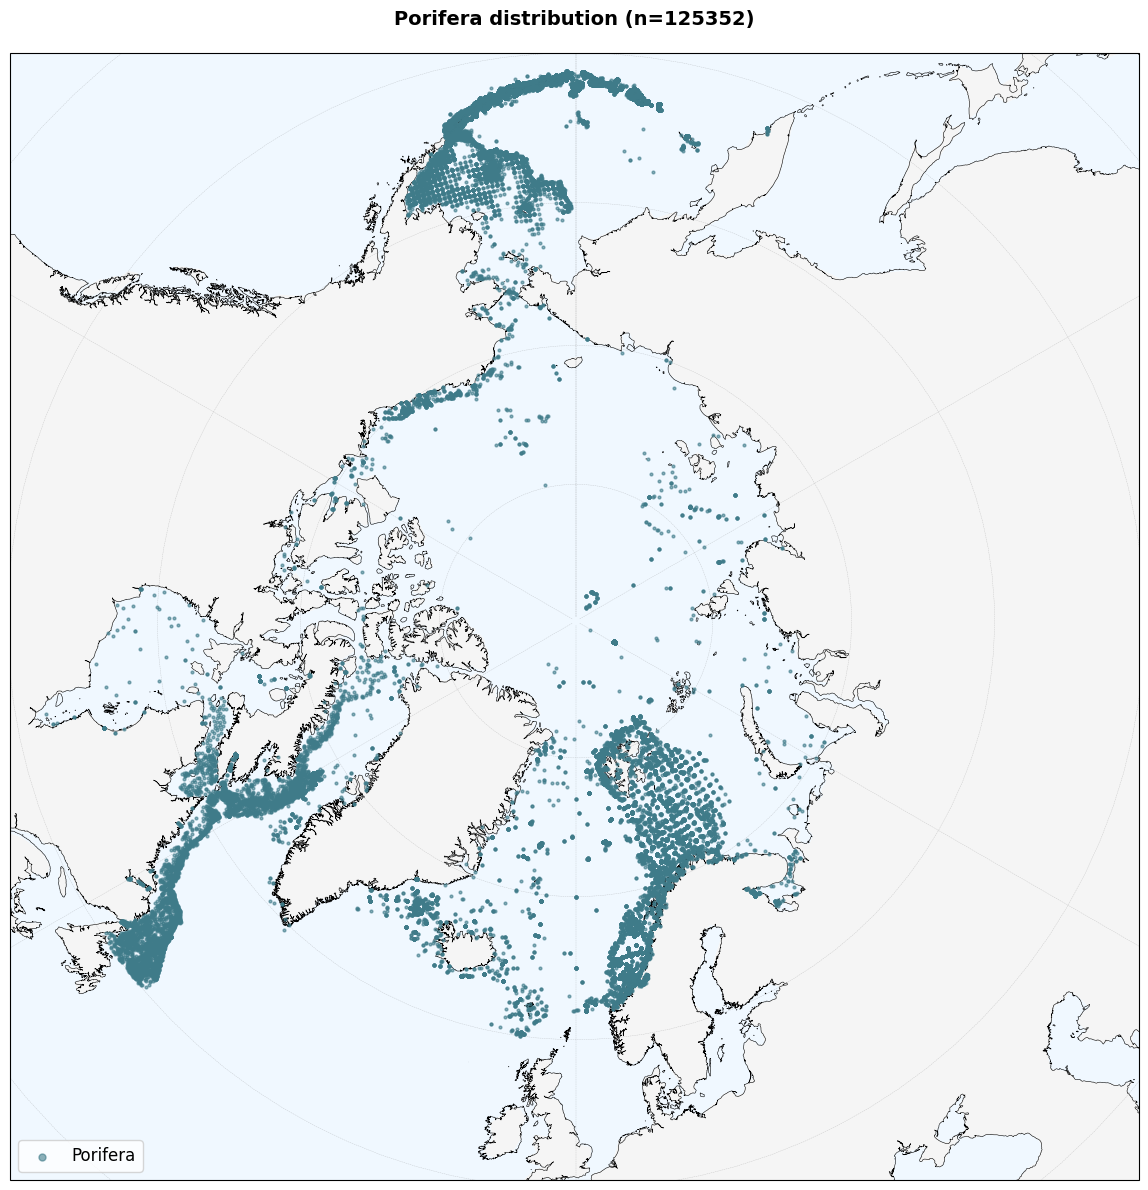

In [7]:
# Load porifera data if not already in memory
if "porifera" not in locals():
    porifera = pd.read_parquet("VME/porifera.parquet")

# Prepare data for plotting
df_map = porifera.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

# Filter to valid coordinates
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Create the map
fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Plot all Porifera records in one style
ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#3F7B89",
    transform=ccrs.PlateCarree(),
    label="Porifera",
    zorder=2,
)

ax.legend(
    loc="lower left",
    frameon=True,
    fontsize=12,
    markerscale=2.5,
)

plt.title(f"Porifera distribution (n={len(df_map)})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("VME/porifera_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

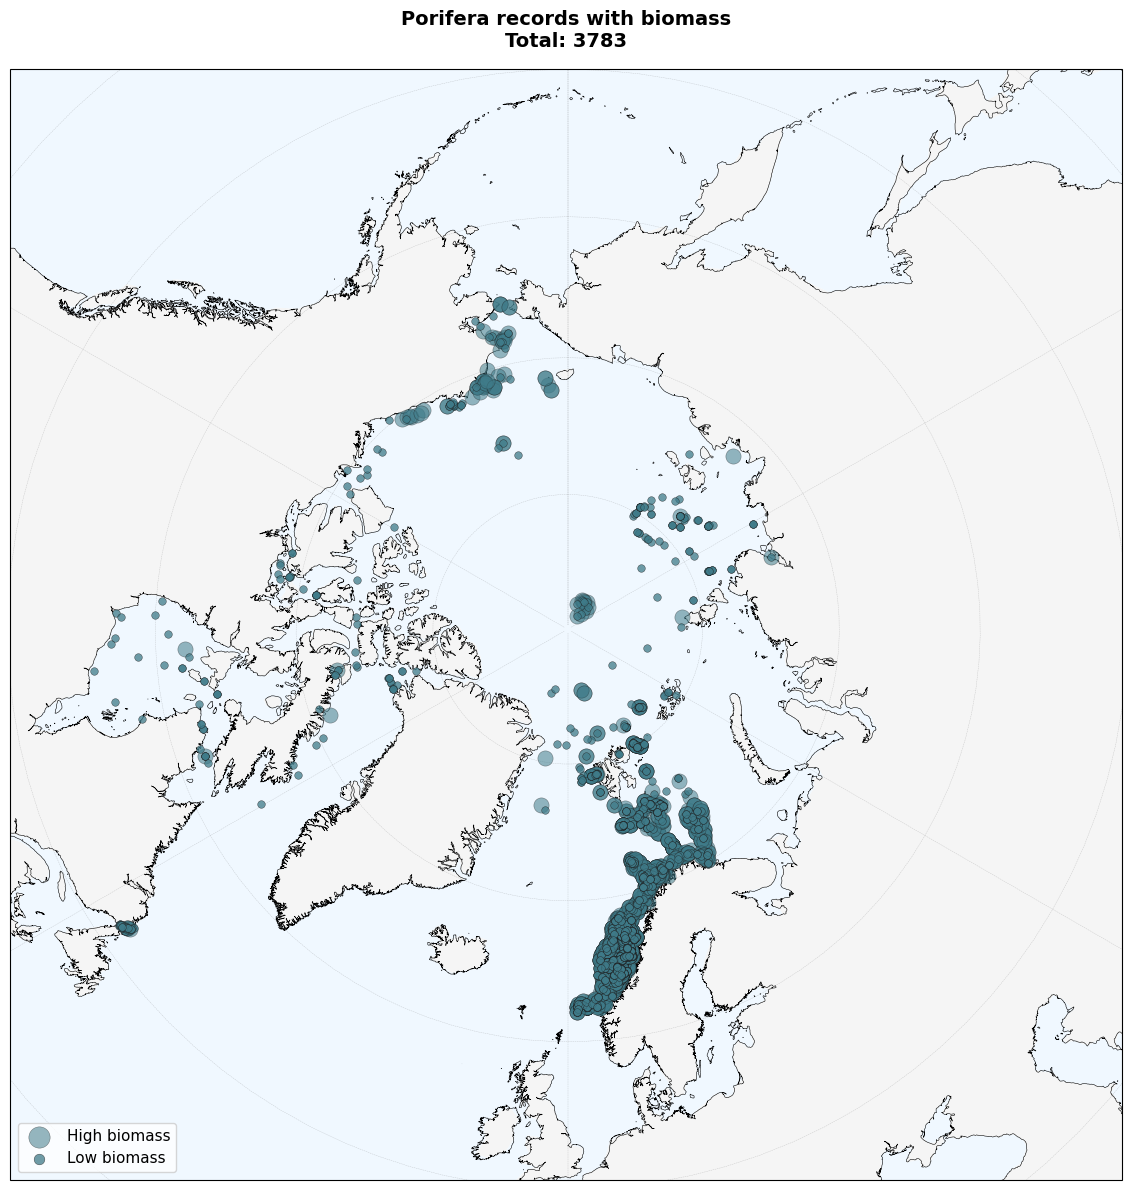

In [8]:
# Map Porifera records with biomass; marker size indicates high/low biomass
if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

df_bio = porifera.copy()

# Clean numeric fields
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

# Keep valid coordinates + rows with biomass
df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
].copy()

if df_bio.empty:
    raise ValueError("No Porifera records with valid positive biomass and coordinates.")

# Classify biomass as high/low based on median
biomass_median = df_bio["biomass_num"].median()
df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

# Define shared style (no Geodia distinction)
point_color = "#3F7B89"
edge_color = "#1F1F1F"
size_high = 120
size_low = 30

# Plot
fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Plot order: large markers first (so small markers appear on top)
df_high = df_bio[df_bio["biomass_category"] == "high"]
ax.scatter(
    df_high["decimalLongitudeStart"].values,
    df_high["decimalLatitudeStart"].values,
    s=size_high,
    c=point_color,
    alpha=0.55,
    edgecolors=edge_color,
    linewidths=0.35,
    transform=ccrs.PlateCarree(),
    zorder=2,
    label="High biomass",
)

df_low = df_bio[df_bio["biomass_category"] == "low"]
ax.scatter(
    df_low["decimalLongitudeStart"].values,
    df_low["decimalLatitudeStart"].values,
    s=size_low,
    c=point_color,
    alpha=0.75,
    edgecolors=edge_color,
    linewidths=0.35,
    transform=ccrs.PlateCarree(),
    zorder=3,
    label="Low biomass",
)

ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)

counts_str = f"Total: {len(df_bio)}"
plt.title(f"Porifera records with biomass\n{counts_str}", fontsize=14, fontweight="bold", pad=16)
plt.tight_layout()
plt.savefig("VME/porifera_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

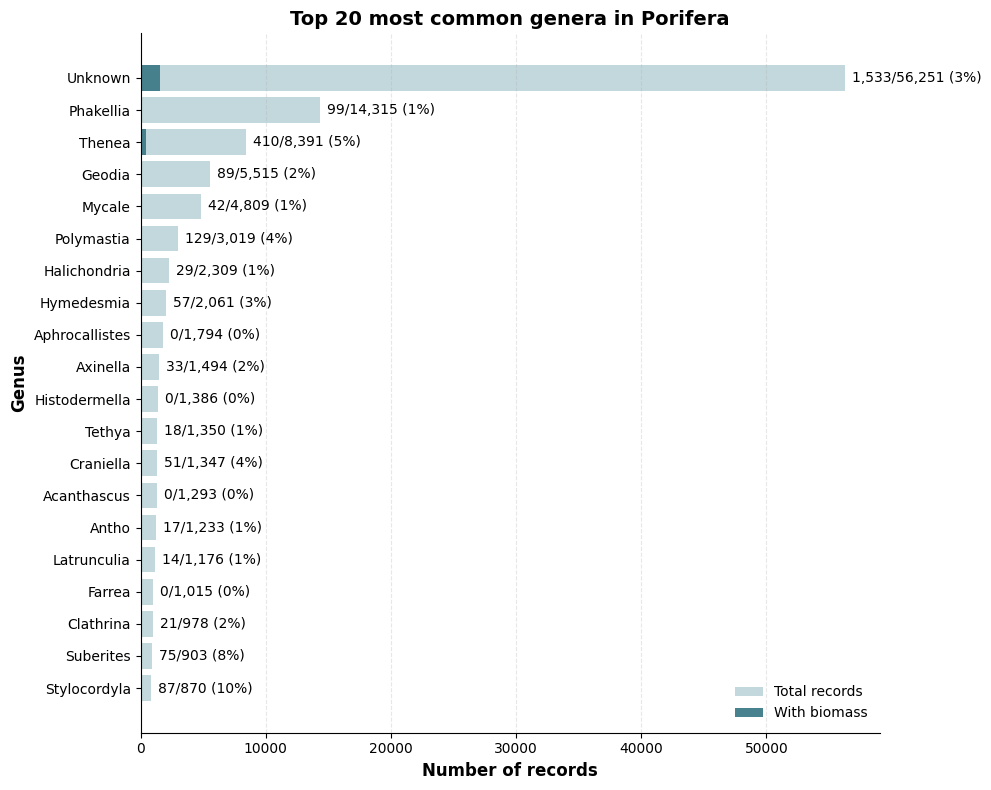

,record_count,biomass_count,biomass_proportion
group,,,
Stylocordyla,870,87,0.1
Suberites,903,75,0.083056
Clathrina,978,21,0.021472
Farrea,1015,0,0.0
Latrunculia,1176,14,0.011905
Antho,1233,17,0.013788
Acanthascus,1293,0,0.0
Craniella,1347,51,0.037862
Tethya,1350,18,0.013333


In [9]:
# Visualize most common genera in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in VME/porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["genus"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

genus_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
genus_stats["biomass_proportion"] = genus_stats["biomass_count"] / genus_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

# Full bar = total records
ax.barh(genus_stats.index, genus_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
# Colored segment = records with biomass present
ax.barh(genus_stats.index, genus_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Genus", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common genera in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = genus_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(genus_stats["record_count"], genus_stats["biomass_count"], genus_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("VME/porifera_top_genera.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

genus_stats[["record_count", "biomass_count", "biomass_proportion"]]

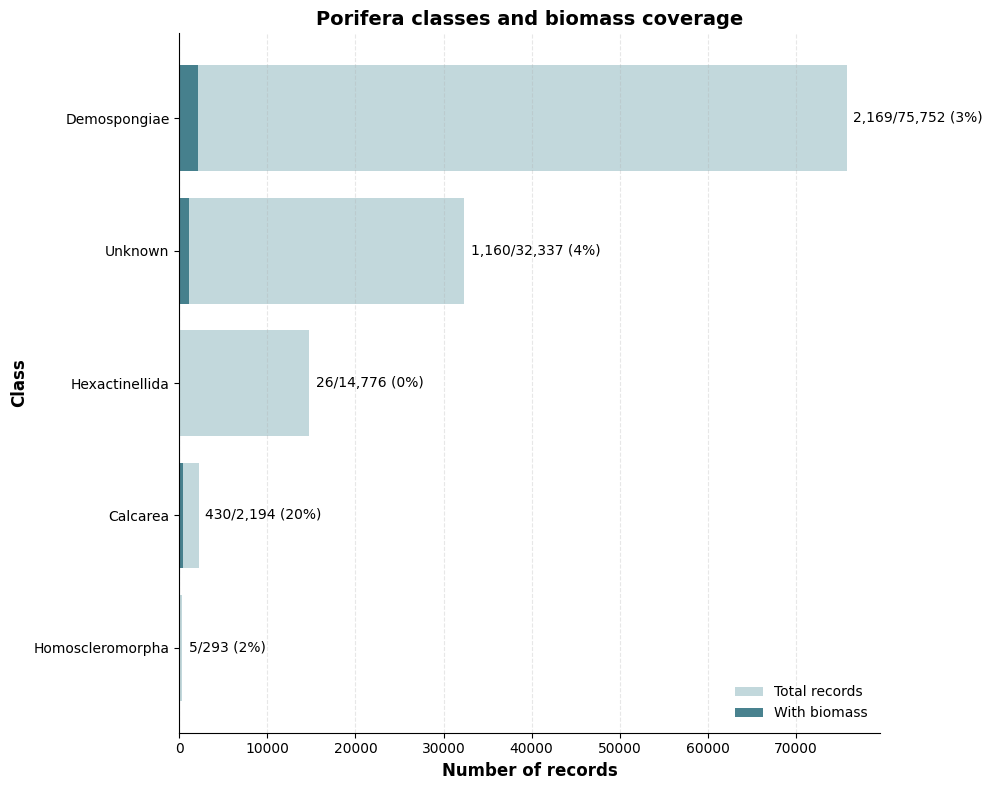

,record_count,biomass_count,biomass_proportion
group,,,
Homoscleromorpha,293,5,0.017065
Calcarea,2194,430,0.195989
Hexactinellida,14776,26,0.00176
Unknown,32337,1160,0.035872
Demospongiae,75752,2169,0.028633


In [10]:
# Visualize most common classes in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in VME/porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["class"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

class_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
class_stats["biomass_proportion"] = class_stats["biomass_count"] / class_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(class_stats.index, class_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(class_stats.index, class_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Class", fontsize=12, fontweight="bold")
ax.set_title(f"Porifera classes and biomass coverage", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = class_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(class_stats["record_count"], class_stats["biomass_count"], class_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("VME/porifera_top_classes.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

class_stats[["record_count", "biomass_count", "biomass_proportion"]]

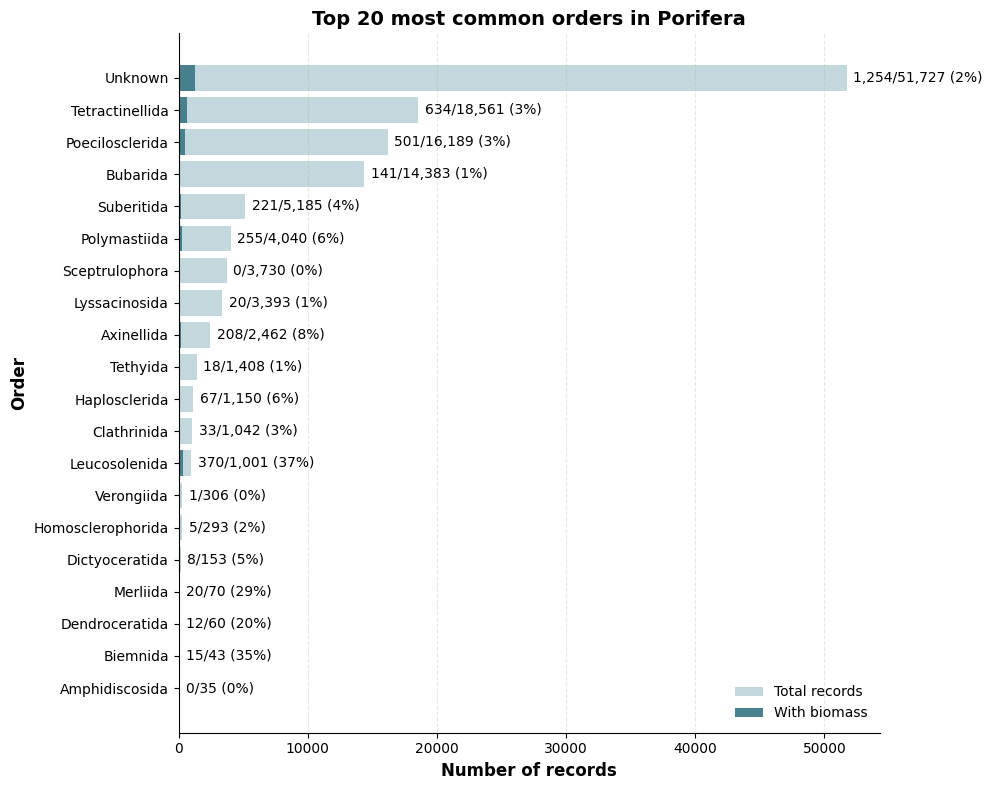

,record_count,biomass_count,biomass_proportion
group,,,
Amphidiscosida,35,0,0.0
Biemnida,43,15,0.348837
Dendroceratida,60,12,0.2
Merliida,70,20,0.285714
Dictyoceratida,153,8,0.052288
Homosclerophorida,293,5,0.017065
Verongiida,306,1,0.003268
Leucosolenida,1001,370,0.36963
Clathrinida,1042,33,0.03167


In [11]:
# Visualize most common orders in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in VME/porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["order"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

order_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
order_stats["biomass_proportion"] = order_stats["biomass_count"] / order_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(order_stats.index, order_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(order_stats.index, order_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Order", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common orders in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = order_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(order_stats["record_count"], order_stats["biomass_count"], order_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("VME/porifera_top_orders.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

order_stats[["record_count", "biomass_count", "biomass_proportion"]]

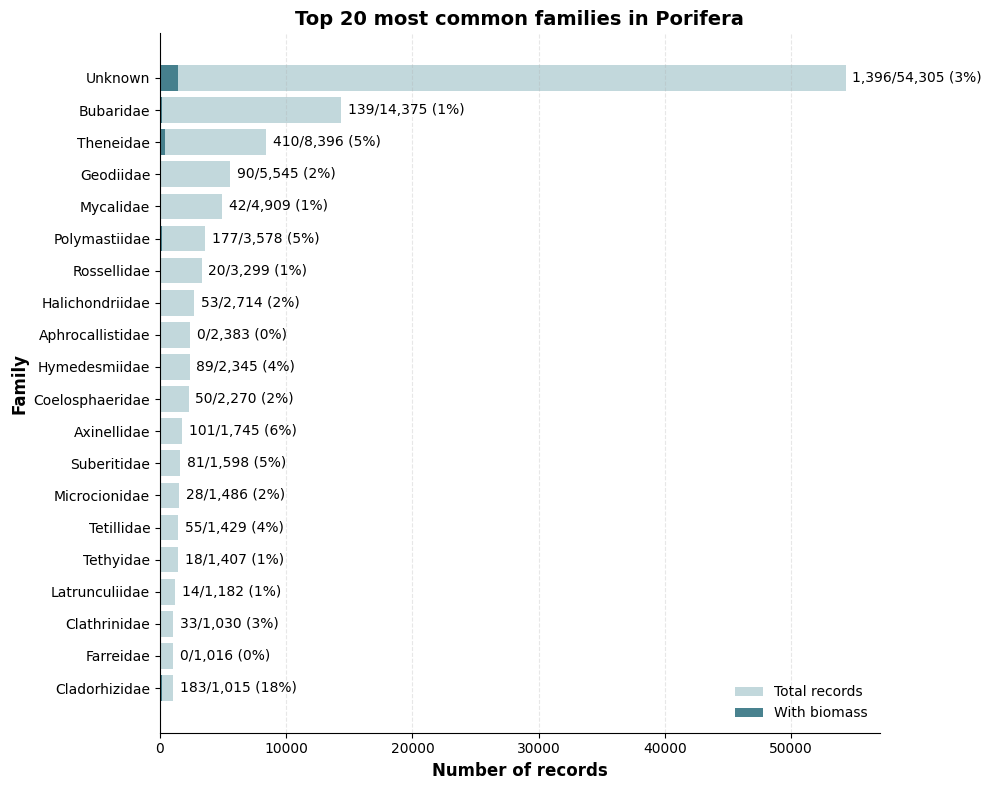

,record_count,biomass_count,biomass_proportion
group,,,
Cladorhizidae,1015,183,0.180296
Farreidae,1016,0,0.0
Clathrinidae,1030,33,0.032039
Latrunculiidae,1182,14,0.011844
Tethyidae,1407,18,0.012793
Tetillidae,1429,55,0.038488
Microcionidae,1486,28,0.018843
Suberitidae,1598,81,0.050688
Axinellidae,1745,101,0.05788


In [12]:
# Visualize most common families in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in VME/porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

family_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
family_stats["biomass_proportion"] = family_stats["biomass_count"] / family_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(family_stats.index, family_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(family_stats.index, family_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Family", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common families in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = family_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(family_stats["record_count"], family_stats["biomass_count"], family_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("VME/porifera_top_families.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

family_stats[["record_count", "biomass_count", "biomass_proportion"]]

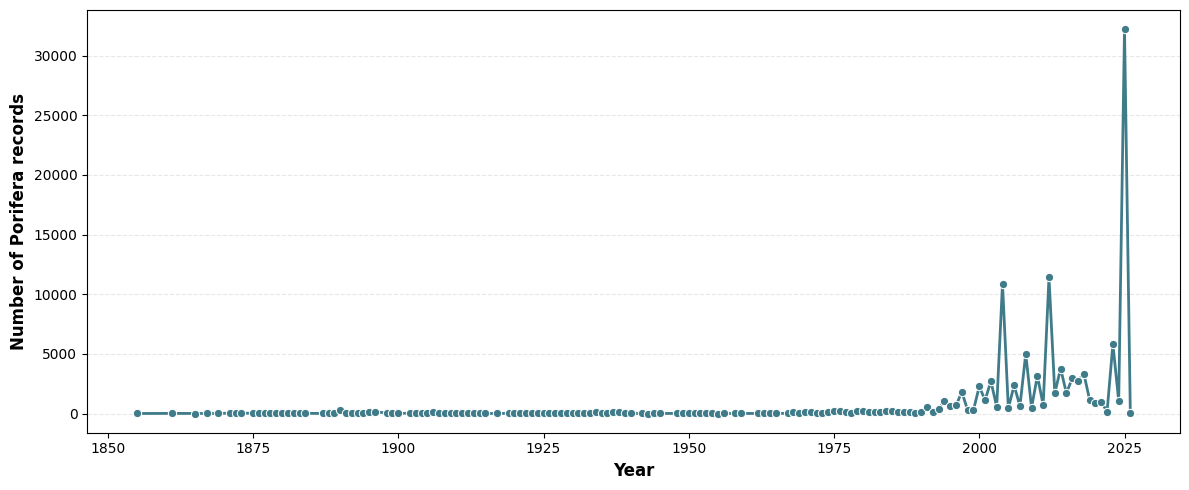

,year,record_count
0,1855,2
1,1861,11
2,1865,1
3,1867,2
4,1869,2
...,...,...
142,2022,161
143,2023,5816
144,2024,1049
145,2025,32218


In [13]:
# Timeline: number of Porifera records per year
if "porifera" not in globals():
    porifera = pd.read_parquet("VME/porifera.parquet")

porifera_timeline = (
    porifera.assign(year=pd.to_numeric(porifera["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=porifera_timeline, x="year", y="record_count", marker="o", color="#3F7B89", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Porifera records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("VME/porifera_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

porifera_timeline

# VME Cnidaria

In [14]:
# Remove selected Cnidaria orders
excluded_orders = {
    "Coronatae",
    "Limnomedusae",
    "Trachymedusae",
    "Semaeostomeae",
}

# Load cnidaria if not already in memory
if "cnidaria" not in globals():
    if os.path.exists("VME/cnidaria.parquet"):
        cnidaria = pd.read_parquet("VME/cnidaria.parquet")
    else:
        src = pd.read_parquet("Final/merged_all_final.parquet")
        cnidaria = src[src["phylum"] == "Cnidaria"].copy()

before_n = len(cnidaria)

mask_excluded = cnidaria["order"].astype("string").str.strip().isin(excluded_orders)
cnidaria = cnidaria.loc[~mask_excluded].copy()

after_n = len(cnidaria)
removed_n = before_n - after_n

# Save filtered dataset
cnidaria.to_parquet("VME/cnidaria.parquet", index=False)

print(f"Removed records: {removed_n:,}")
print(f"Remaining Cnidaria records: {after_n:,}")

Removed records: 0
Remaining Cnidaria records: 105,666


Cnidaria records: 105,666
Saved: VME/column_coverage_cnidaria.csv


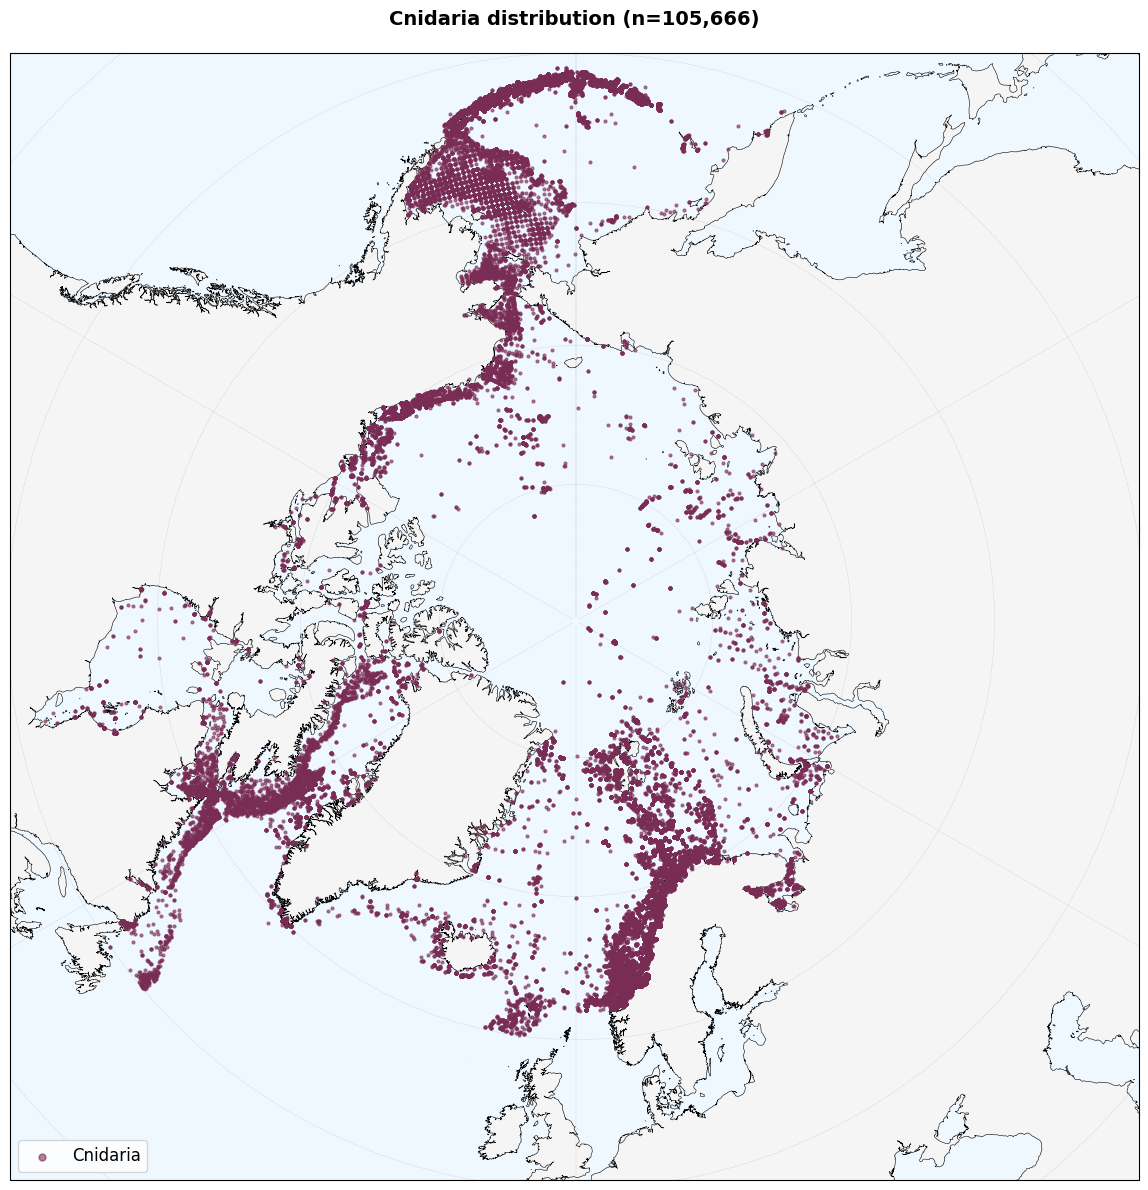

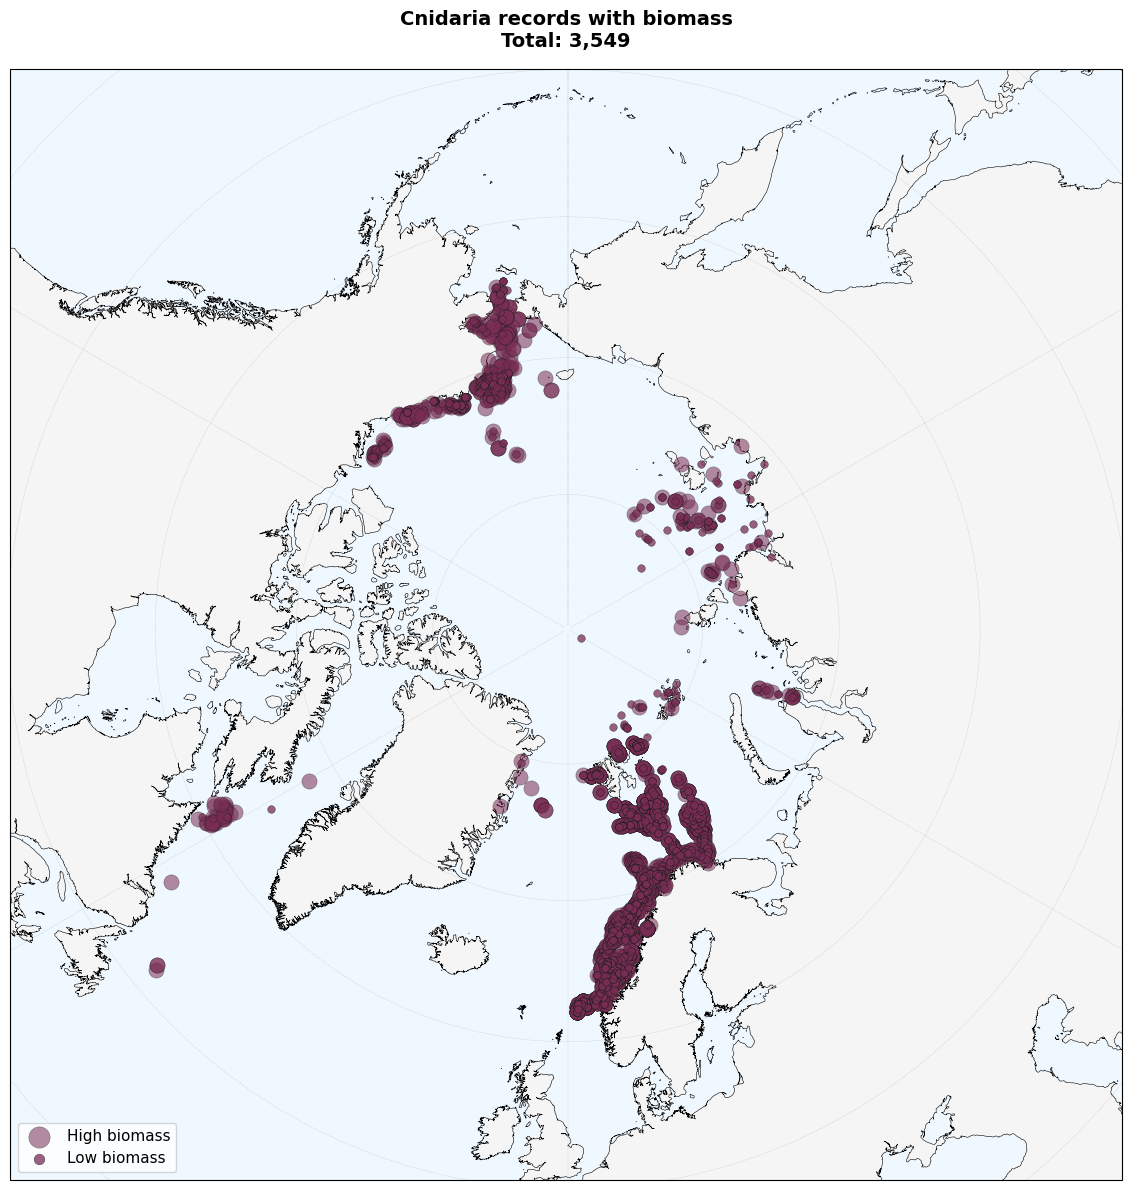

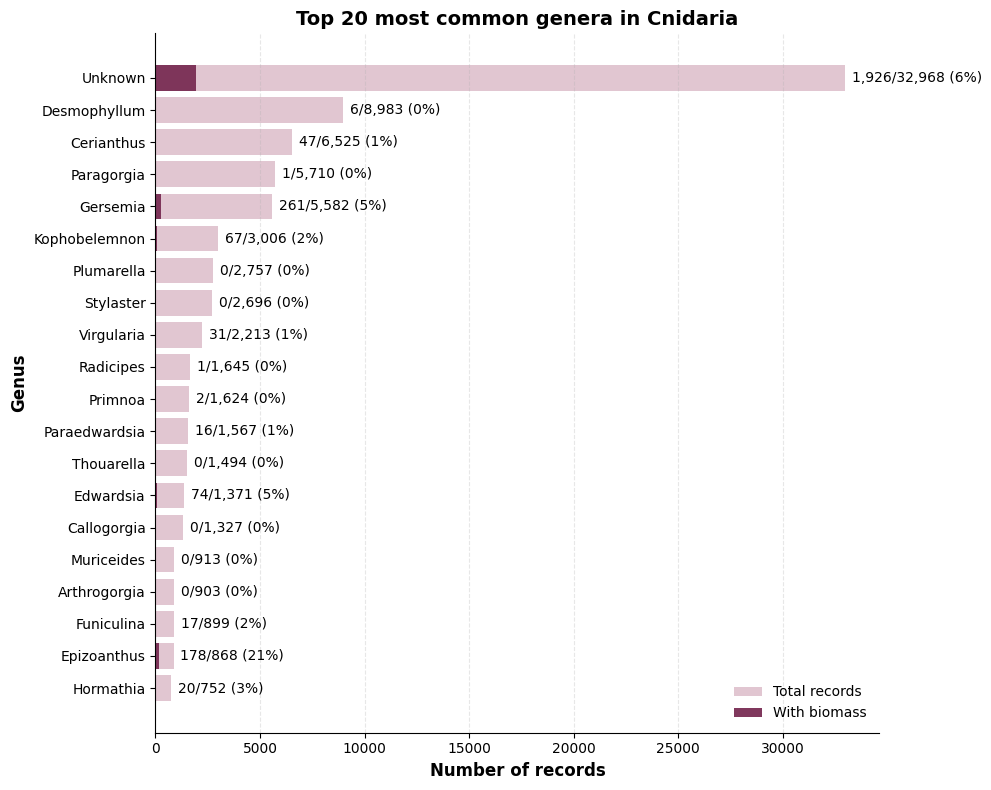

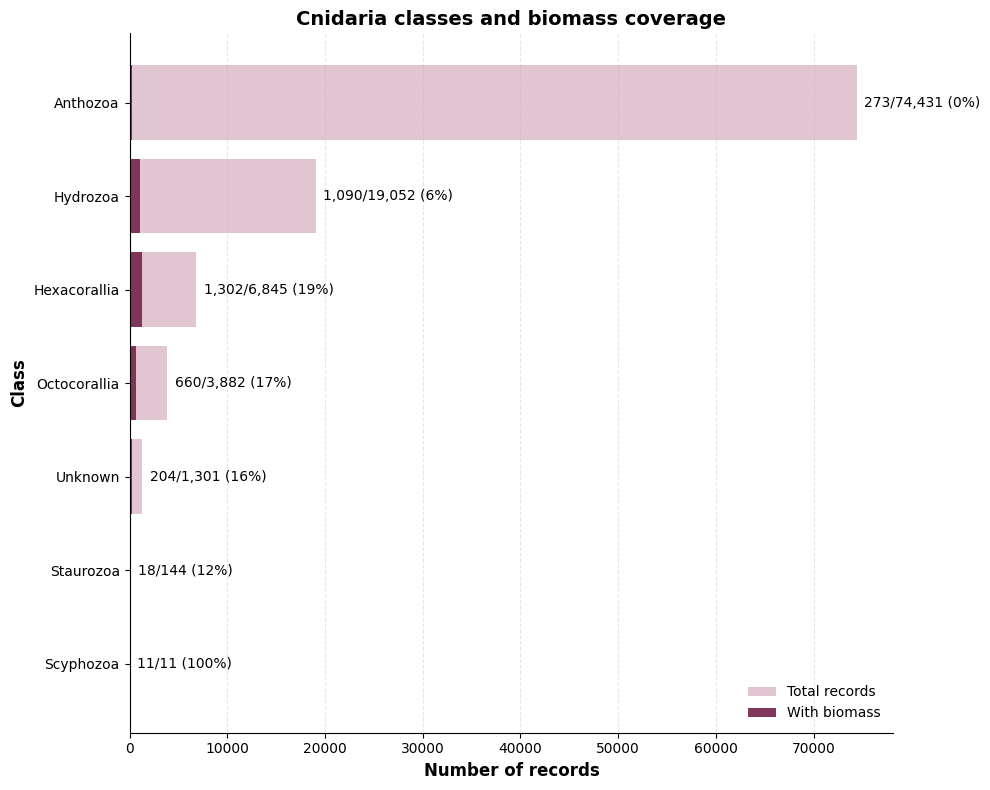

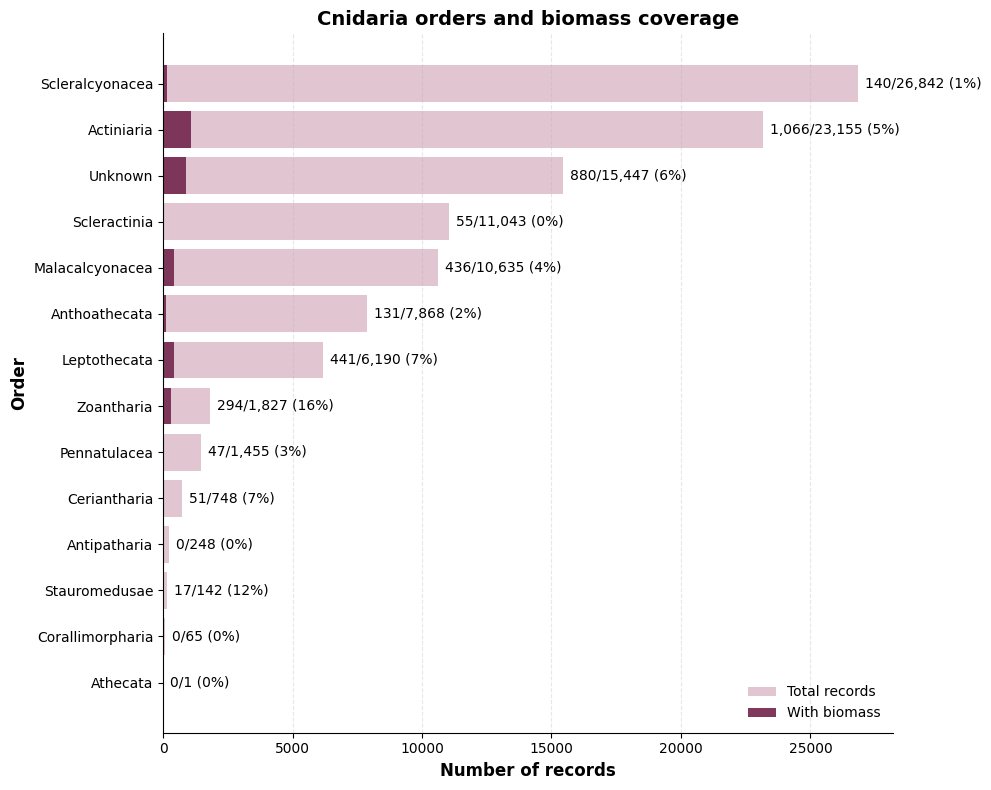

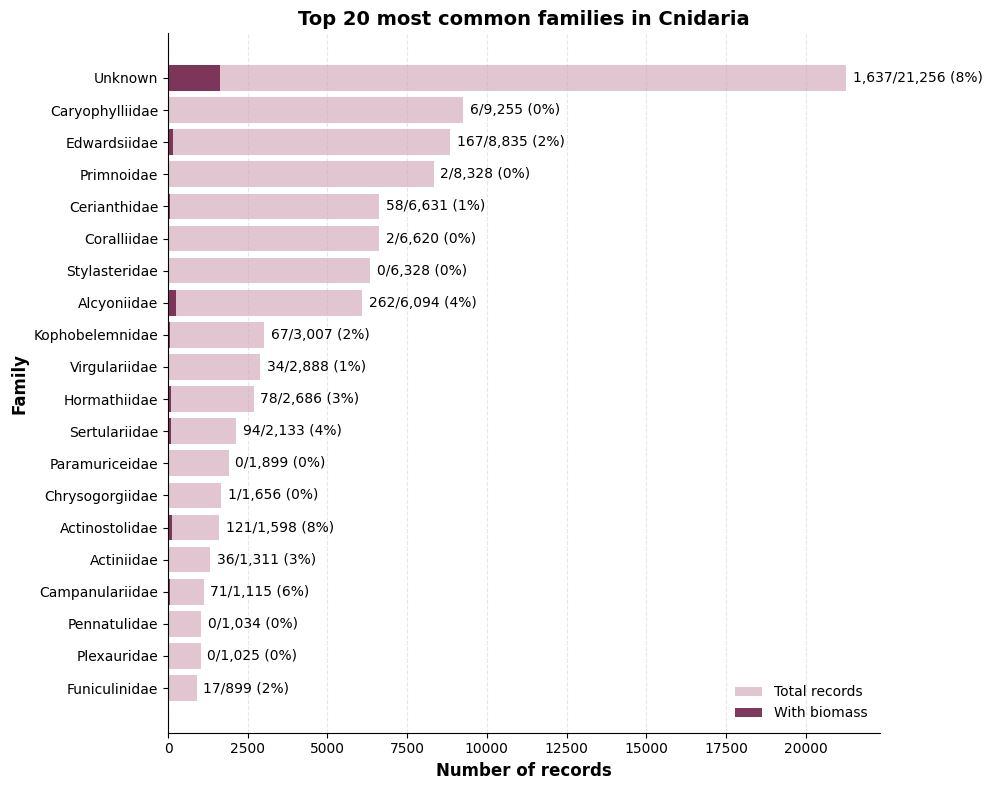

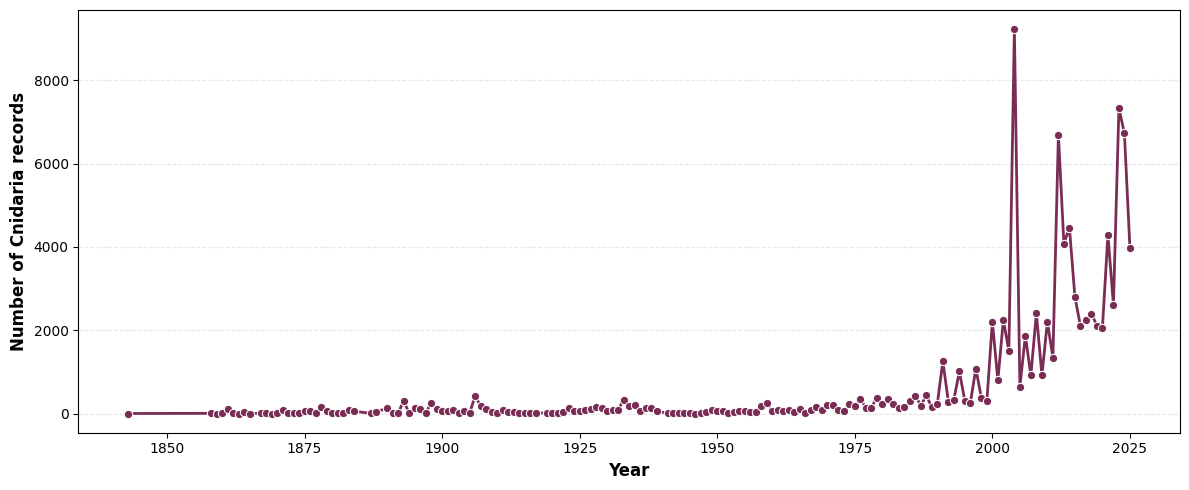

,year,record_count
0,1843,1
1,1858,5
2,1859,1
3,1860,3
4,1861,108
...,...,...
158,2021,4295
159,2022,2616
160,2023,7332
161,2024,6725


In [15]:
# Cnidaria workflow (analogous to cells 49â€“57)

# 0) Load or build cnidaria dataset
cnidaria_path = "VME/cnidaria.parquet"
if os.path.exists(cnidaria_path):
    cnidaria = pd.read_parquet(cnidaria_path)
else:
    src = pd.read_parquet("Final/merged_all_final.parquet")
    cnidaria = src[src["phylum"] == "Cnidaria"].copy()
    cnidaria.to_parquet(cnidaria_path, index=False)

print(f"Cnidaria records: {len(cnidaria):,}")

# 1) Column coverage (like cell 49)
total_rows = len(cnidaria)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_cnidaria = pd.DataFrame({
    "column": cnidaria.columns,
    "non_missing": [non_missing_mask(cnidaria[c]).sum() for c in cnidaria.columns],
})
coverage_cnidaria["total_rows"] = total_rows
coverage_cnidaria["coverage_percent"] = (coverage_cnidaria["non_missing"] / total_rows * 100).round(2)
coverage_cnidaria = coverage_cnidaria.sort_values("coverage_percent", ascending=False).reset_index(drop=True)
coverage_cnidaria.to_csv("VME/column_coverage_cnidaria.csv", index=False)
print("Saved: VME/column_coverage_cnidaria.csv")

# 2) Distribution map (like cell 50)
cn_map = cnidaria.copy()
cn_map["decimalLatitudeStart"] = pd.to_numeric(cn_map["decimalLatitudeStart"], errors="coerce")
cn_map["decimalLongitudeStart"] = pd.to_numeric(cn_map["decimalLongitudeStart"], errors="coerce")
cn_map = cn_map[
    cn_map["decimalLatitudeStart"].between(-90, 90)
    & cn_map["decimalLongitudeStart"].between(-180, 180)
].copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    cn_map["decimalLongitudeStart"].values,
    cn_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#792D54",
    transform=ccrs.PlateCarree(),
    label="Cnidaria",
    zorder=2,
)
ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Cnidaria distribution (n={len(cn_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("VME/cnidaria_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (like cell 51)
cn_bio = cnidaria.copy()
cn_bio["decimalLatitudeStart"] = pd.to_numeric(cn_bio["decimalLatitudeStart"], errors="coerce")
cn_bio["decimalLongitudeStart"] = pd.to_numeric(cn_bio["decimalLongitudeStart"], errors="coerce")
cn_bio["biomass_num"] = pd.to_numeric(cn_bio["biomass"], errors="coerce")
cn_bio = cn_bio[
    cn_bio["decimalLatitudeStart"].between(-90, 90)
    & cn_bio["decimalLongitudeStart"].between(-180, 180)
    & cn_bio["biomass_num"].notna()
    & (cn_bio["biomass_num"] > 0)
].copy()

if not cn_bio.empty:
    med = cn_bio["biomass_num"].median()
    cn_bio["biomass_category"] = np.where(cn_bio["biomass_num"] >= med, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = cn_bio[cn_bio["biomass_category"] == "high"]
    low = cn_bio[cn_bio["biomass_category"] == "low"]

    ax.scatter(high["decimalLongitudeStart"], high["decimalLatitudeStart"], s=120, c="#792D54",
               alpha=0.55, edgecolors=edge_color, linewidths=0.35,
               transform=ccrs.PlateCarree(), zorder=2, label="High biomass")
    ax.scatter(low["decimalLongitudeStart"], low["decimalLatitudeStart"], s=30, c="#792D54",
               alpha=0.75, edgecolors=edge_color, linewidths=0.35,
               transform=ccrs.PlateCarree(), zorder=3, label="Low biomass")

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Cnidaria records with biomass\nTotal: {len(cn_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("VME/cnidaria_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
else:
    print("No Cnidaria records with valid positive biomass for biomass map.")

# 4) Top taxa + biomass overlay (like cells 52â€“55)
def plot_top_taxa(df, rank_col, out_png, ylab, title, top_n=20):
    biomass_has = df["biomass"].notna() & df["biomass"].astype("string").str.strip().ne("")
    tmp = df.copy()
    tmp["group"] = tmp[rank_col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
    tmp["has_biomass"] = biomass_has

    stats = (
        tmp.groupby("group", dropna=False)
        .agg(record_count=("group", "size"), biomass_count=("has_biomass", "sum"))
        .sort_values("record_count", ascending=False)
        .head(top_n)
        .sort_values("record_count", ascending=True)
    )
    stats["biomass_proportion"] = stats["biomass_count"] / stats["record_count"]

    plt.figure(figsize=(10, 8))
    ax = plt.gca()
    ax.barh(stats.index, stats["record_count"], color="#E0C3CF", alpha=0.95, label="Total records")
    ax.barh(stats.index, stats["biomass_count"], color="#792D54", alpha=0.95, label="With biomass")
    ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
    ax.set_ylabel(ylab, fontsize=12, fontweight="bold")
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=10)

    max_count_local = stats["record_count"].max()
    for idx, (tot, bio, pr) in enumerate(zip(stats["record_count"], stats["biomass_count"], stats["biomass_proportion"])):
        ax.text(tot + max_count_local * 0.01, idx, f"{bio:,}/{tot:,} ({pr:.0%})", va="center", fontsize=10)

    plt.tight_layout()
    plt.savefig(out_png, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return stats

cn_genus_stats = plot_top_taxa(cnidaria, "genus", "VME/cnidaria_top_genera.png", "Genus", "Top 20 most common genera in Cnidaria")
cn_class_stats = plot_top_taxa(cnidaria, "class", "VME/cnidaria_top_classes.png", "Class", "Cnidaria classes and biomass coverage")
cn_order_stats = plot_top_taxa(cnidaria, "order", "VME/cnidaria_top_orders.png", "Order", "Cnidaria orders and biomass coverage")
cn_family_stats = plot_top_taxa(cnidaria, "family", "VME/cnidaria_top_families.png", "Family", "Top 20 most common families in Cnidaria")

# 5) Timeline (like cell 56)
cnidaria_timeline = (
    cnidaria.assign(year=pd.to_numeric(cnidaria["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=cnidaria_timeline, x="year", y="record_count", marker="o", color="#792D54", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Cnidaria records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("VME/cnidaria_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

cnidaria_timeline

# Siboglinids

Siboglinidae records: 3,621


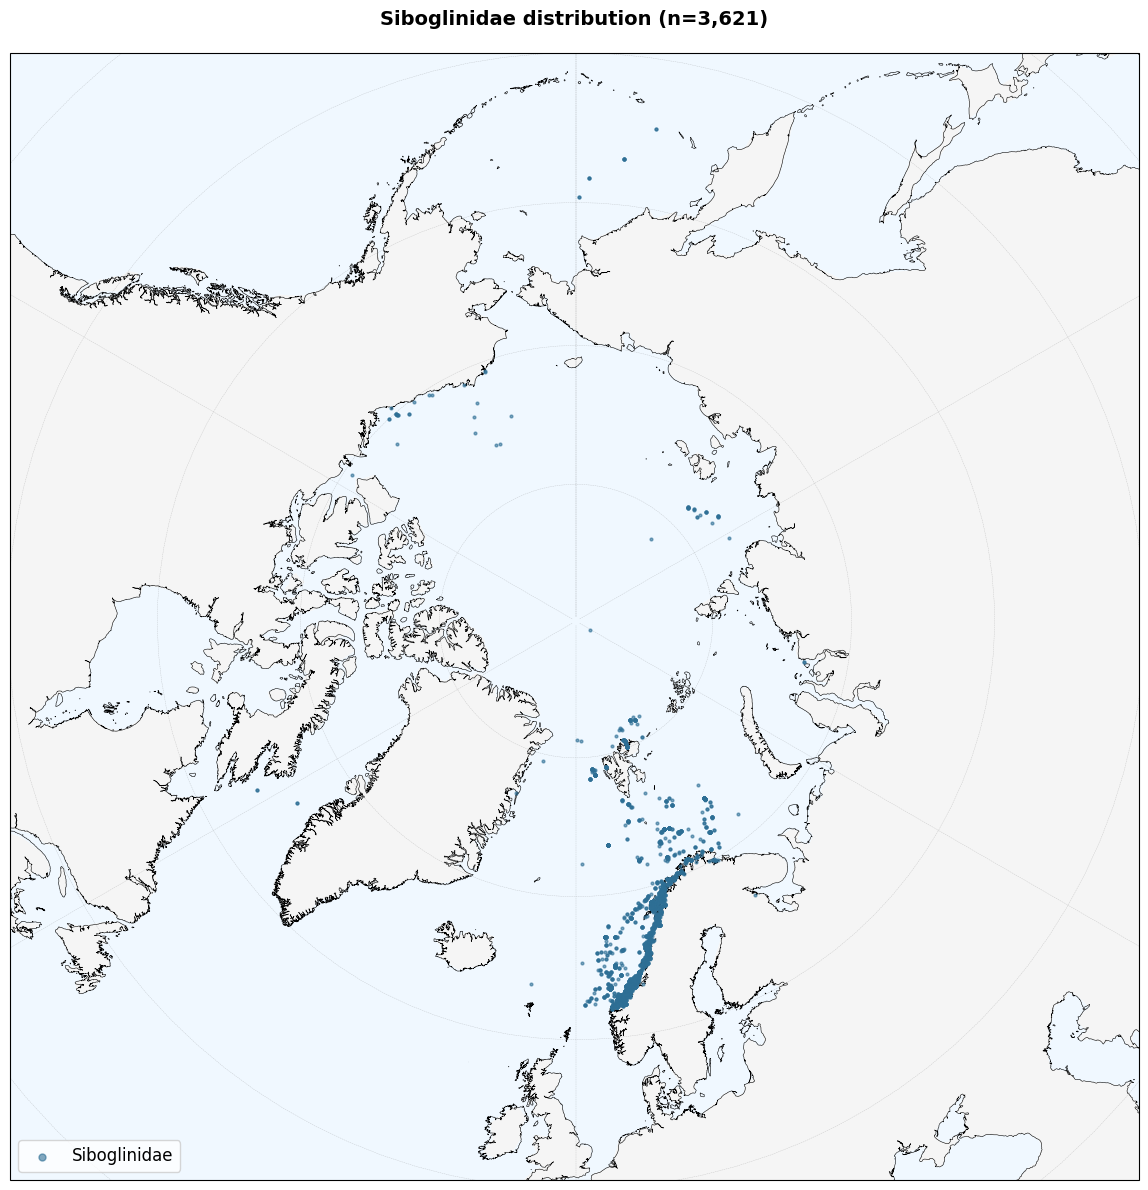

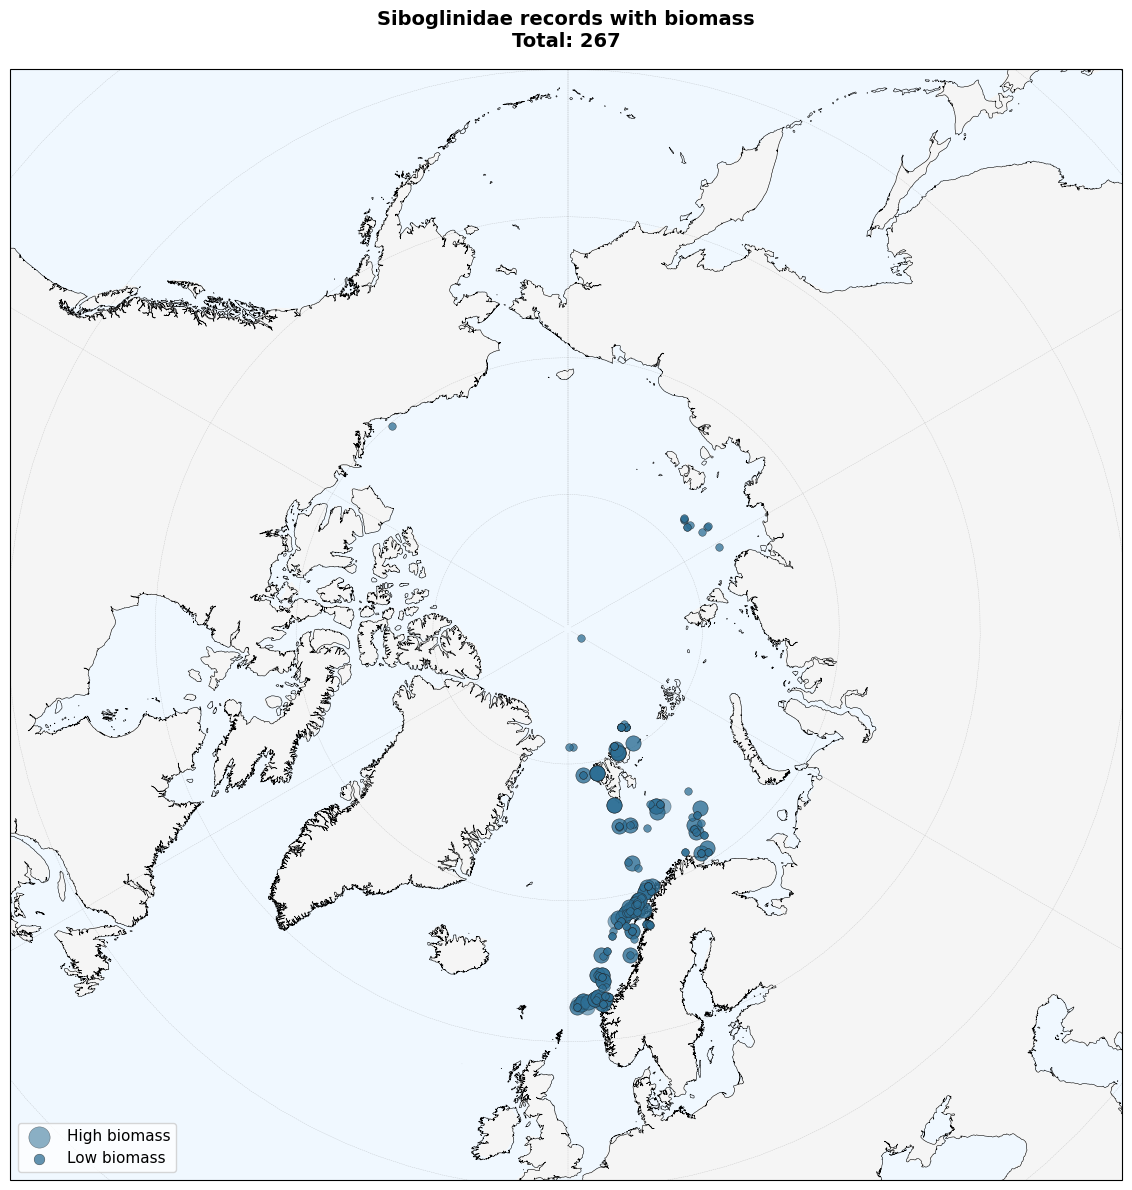

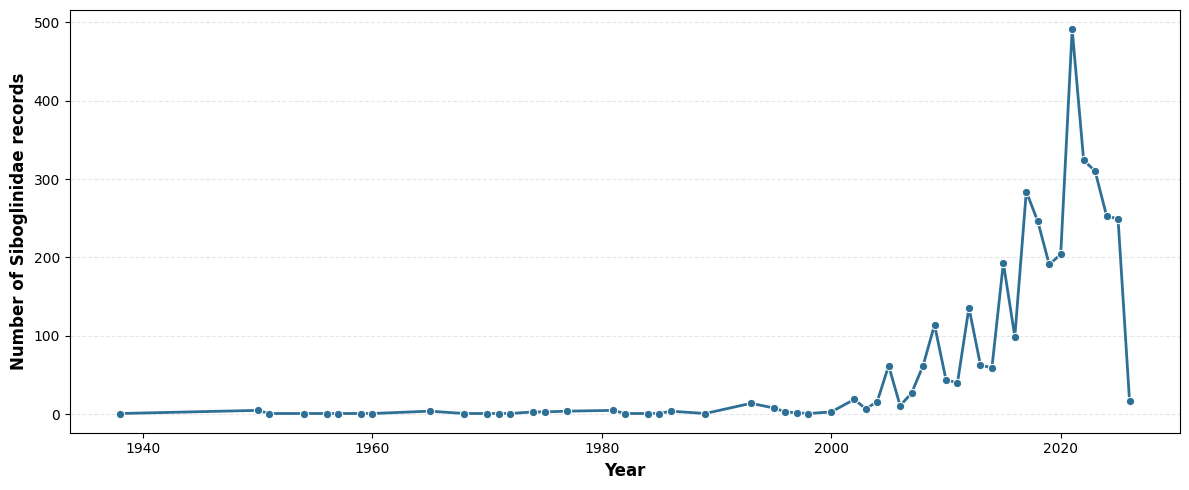

,year,record_count
0,1938,1
1,1950,5
2,1951,1
3,1954,1
4,1956,1
5,1957,1
6,1959,1
7,1960,1
8,1965,4
9,1968,1


In [16]:
# Siboglinidae maps: distribution + biomass (high/low by median)

# 1) Build/load Siboglinidae subset
if "src" in globals():
    base_df = src
elif "all_merged_geo_lme" in globals():
    base_df = all_merged_geo_lme
else:
    base_df = pd.read_parquet("Final/merged_all_final.parquet")

siboglinidae = base_df[
    base_df["family"].astype("string").str.strip().str.lower() == "siboglinidae"
] .copy()

siboglinidae.to_parquet("VME/siboglinidae.parquet", index=False)
print(f"Siboglinidae records: {len(siboglinidae):,}")

if siboglinidae.empty:
    raise ValueError("No records found where family == 'Siboglinidae'.")

# 2) Distribution map
df_map = siboglinidae.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#2E6F95",
    transform=ccrs.PlateCarree(),
    label="Siboglinidae",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Siboglinidae distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("VME/siboglinidae_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = siboglinidae.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Siboglinidae records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    point_color = "#2E6F95"
    edge_color = "#1F1F1F"
    size_high = 120
    size_low = 30

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high,
        c=point_color,
        alpha=0.55,
        edgecolors=edge_color,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low,
        c=point_color,
        alpha=0.75,
        edgecolors=edge_color,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Siboglinidae records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("VME/siboglinidae_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
siboglinidae_timeline = (
    siboglinidae.assign(year=pd.to_numeric(siboglinidae["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=siboglinidae_timeline, x="year", y="record_count", marker="o", color="#2E6F95", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Siboglinidae records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("VME/siboglinidae_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

siboglinidae_timeline

# VME Crinioidea

Crinoidea records: 3,426


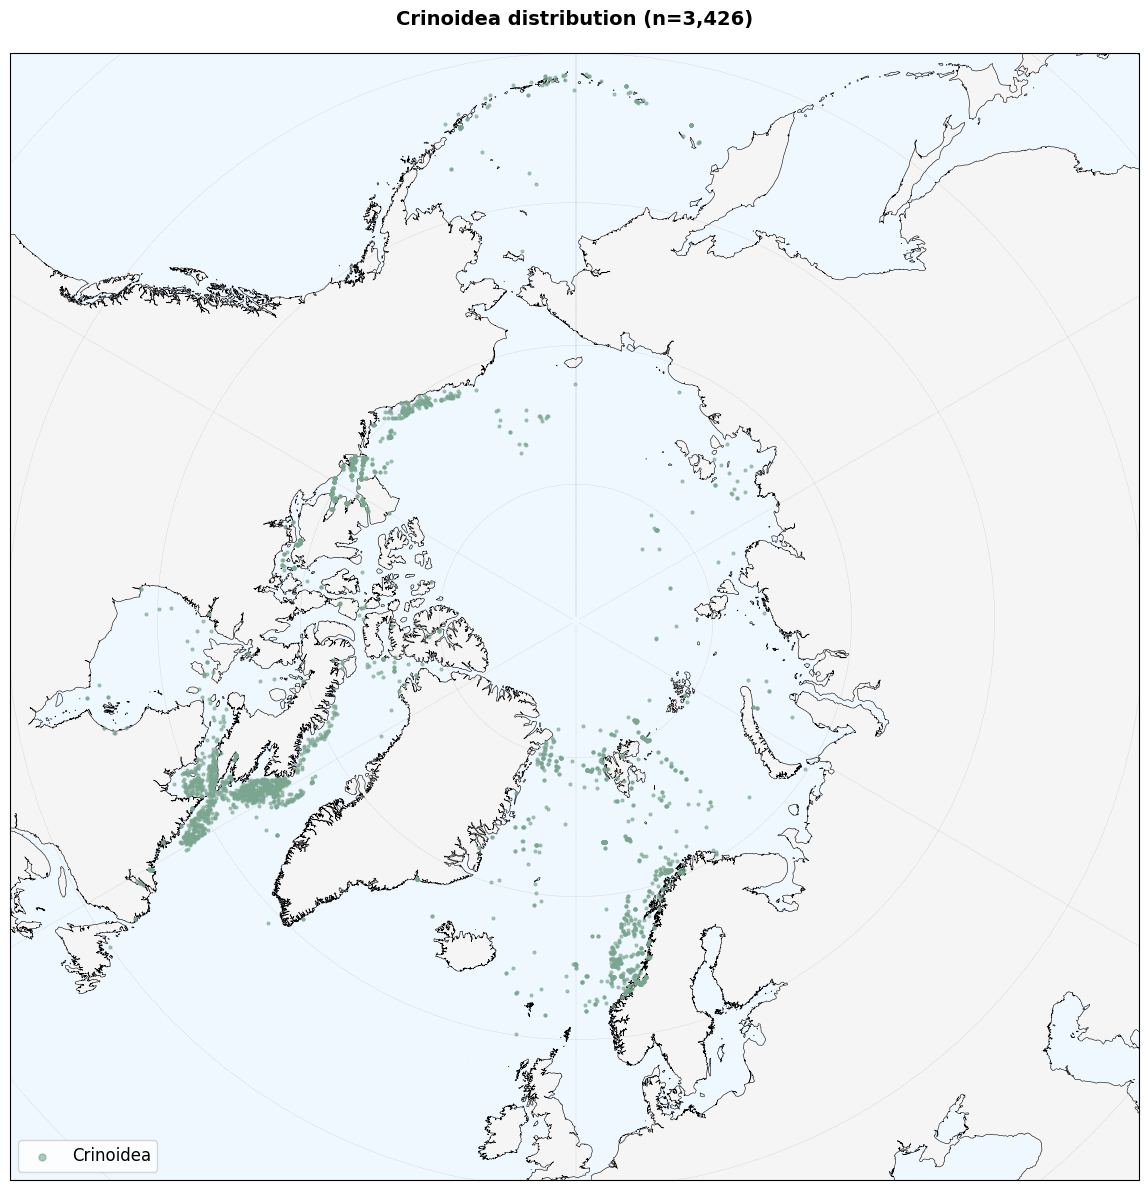

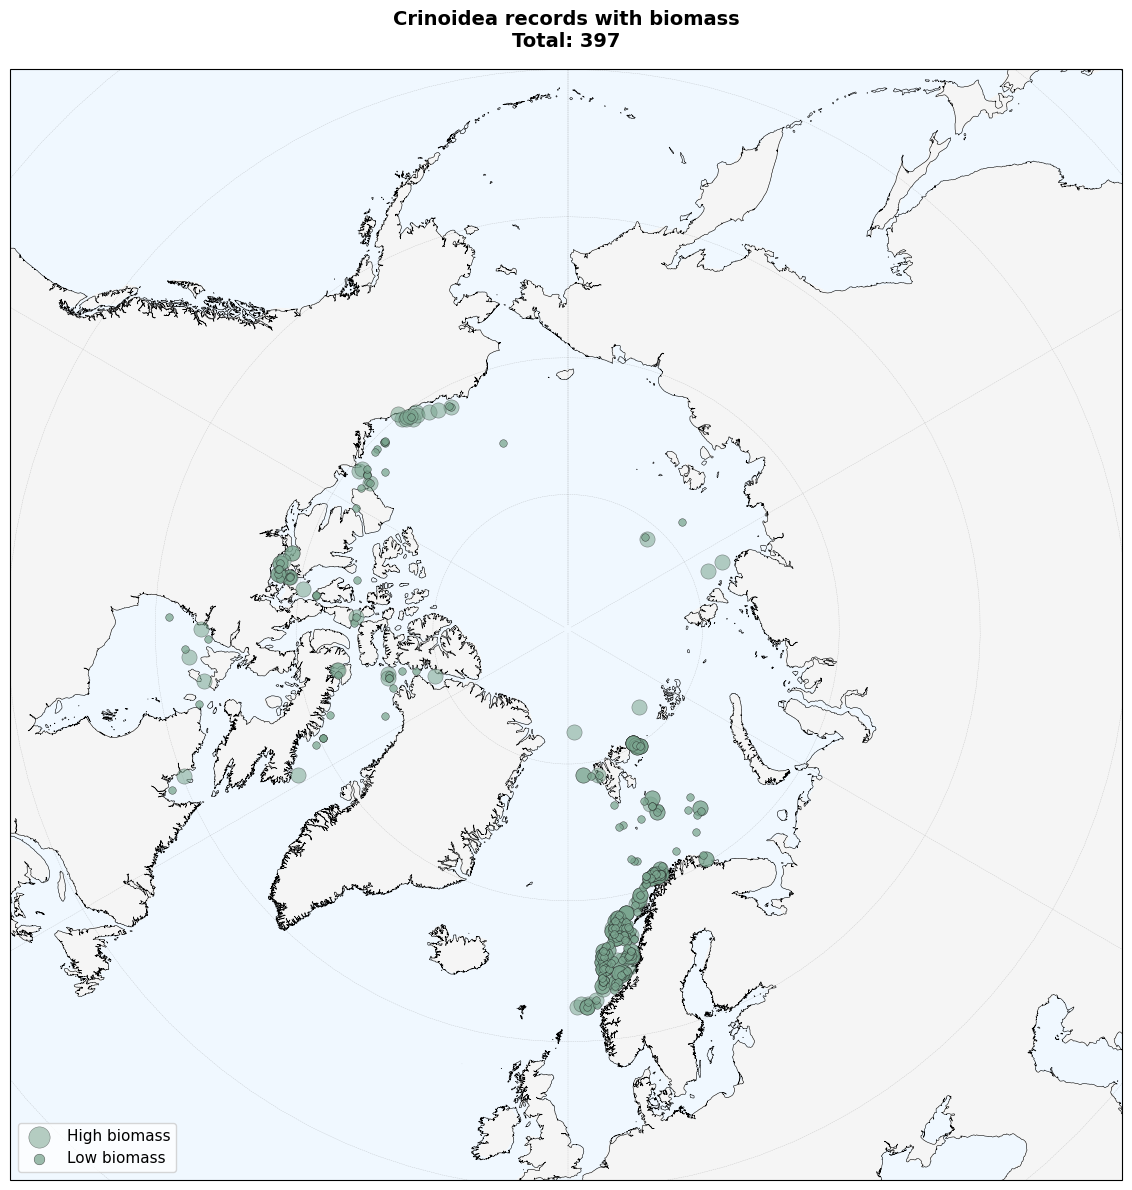

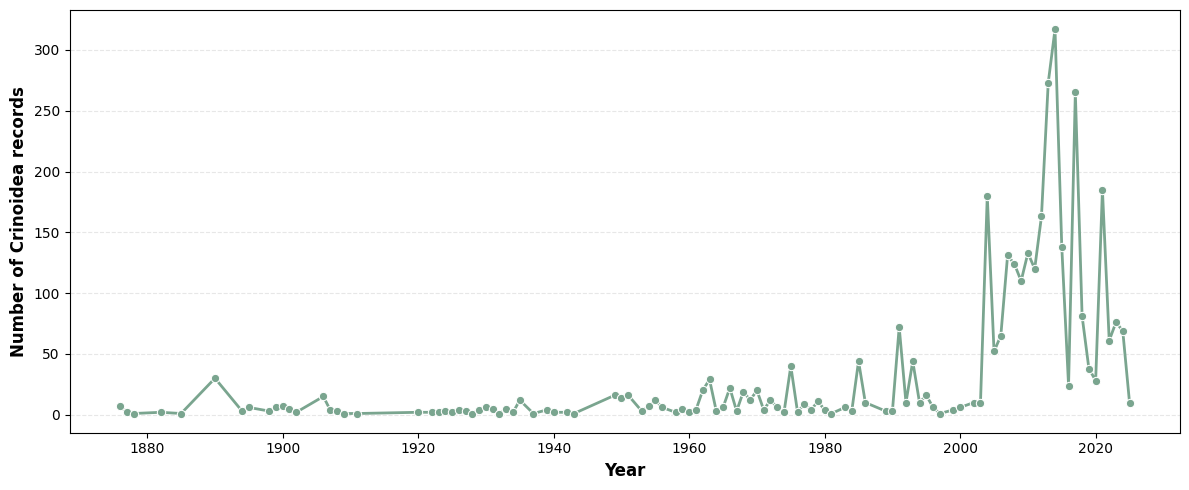

,year,record_count
0,1876,7
1,1877,2
2,1878,1
3,1882,2
4,1885,1
...,...,...
103,2021,185
104,2022,61
105,2023,76
106,2024,69


In [17]:
# Crinoidea maps: distribution + biomass (high/low by median), analogous to Siboglinidae maps

# 1) Build/load Crinoidea subset (class == Crinoidea)
if "src" in globals():
    base_df = src
else:
    base_df = pd.read_parquet("Final/merged_all_final.parquet")

crinoidea = base_df[
    base_df["class"].astype("string").str.strip().str.lower() == "crinoidea"
] .copy()

crinoidea.to_parquet("VME/crinoidea.parquet", index=False)
print(f"Crinoidea records: {len(crinoidea):,}")

if crinoidea.empty:
    raise ValueError("No records found where class == 'Crinoidea'.")

# Fixed style for both maps
map_color = "#7AA58F"
edge_color_local = "#1F1F1F"
size_high_local = size_high if "size_high" in globals() else 120
size_low_local = size_low if "size_low" in globals() else 30

# 2) Distribution map
df_map = crinoidea.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color=map_color,
    transform=ccrs.PlateCarree(),
    label="Crinoidea",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Crinoidea distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("VME/crinoidea_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = crinoidea.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Crinoidea records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high_local,
        c=map_color,
        alpha=0.55,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low_local,
        c=map_color,
        alpha=0.75,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Crinoidea records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("VME/crinoidea_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
crinoidea_timeline = (
    crinoidea.assign(year=pd.to_numeric(crinoidea["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=crinoidea_timeline, x="year", y="record_count", marker="o", color=map_color, linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Crinoidea records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("VME/crinoidea_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

crinoidea_timeline

# Bryozoa

Bryozoa records: 28,608


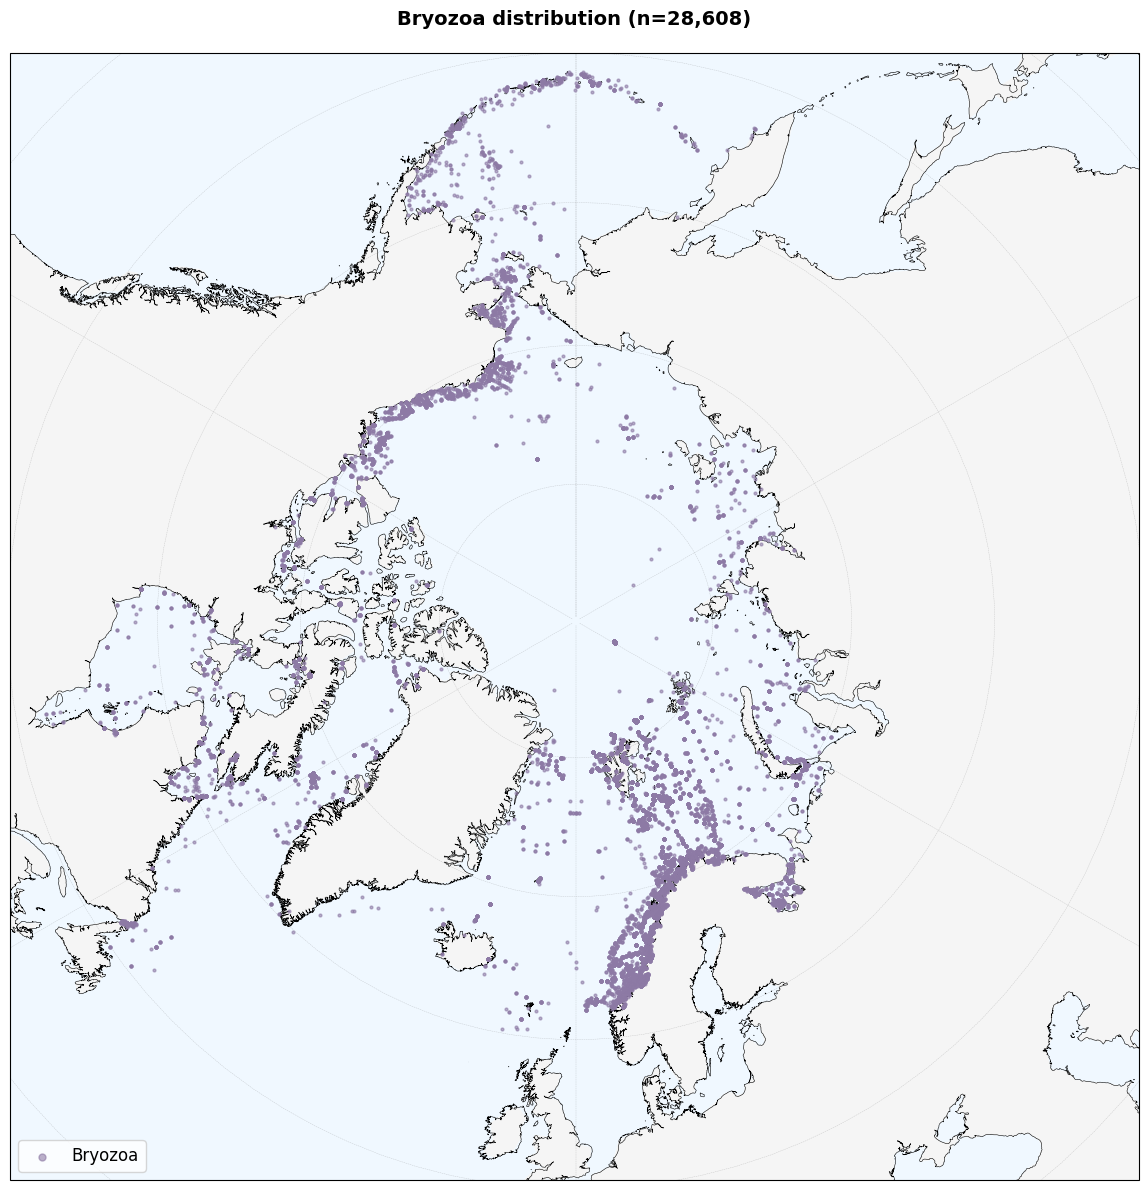

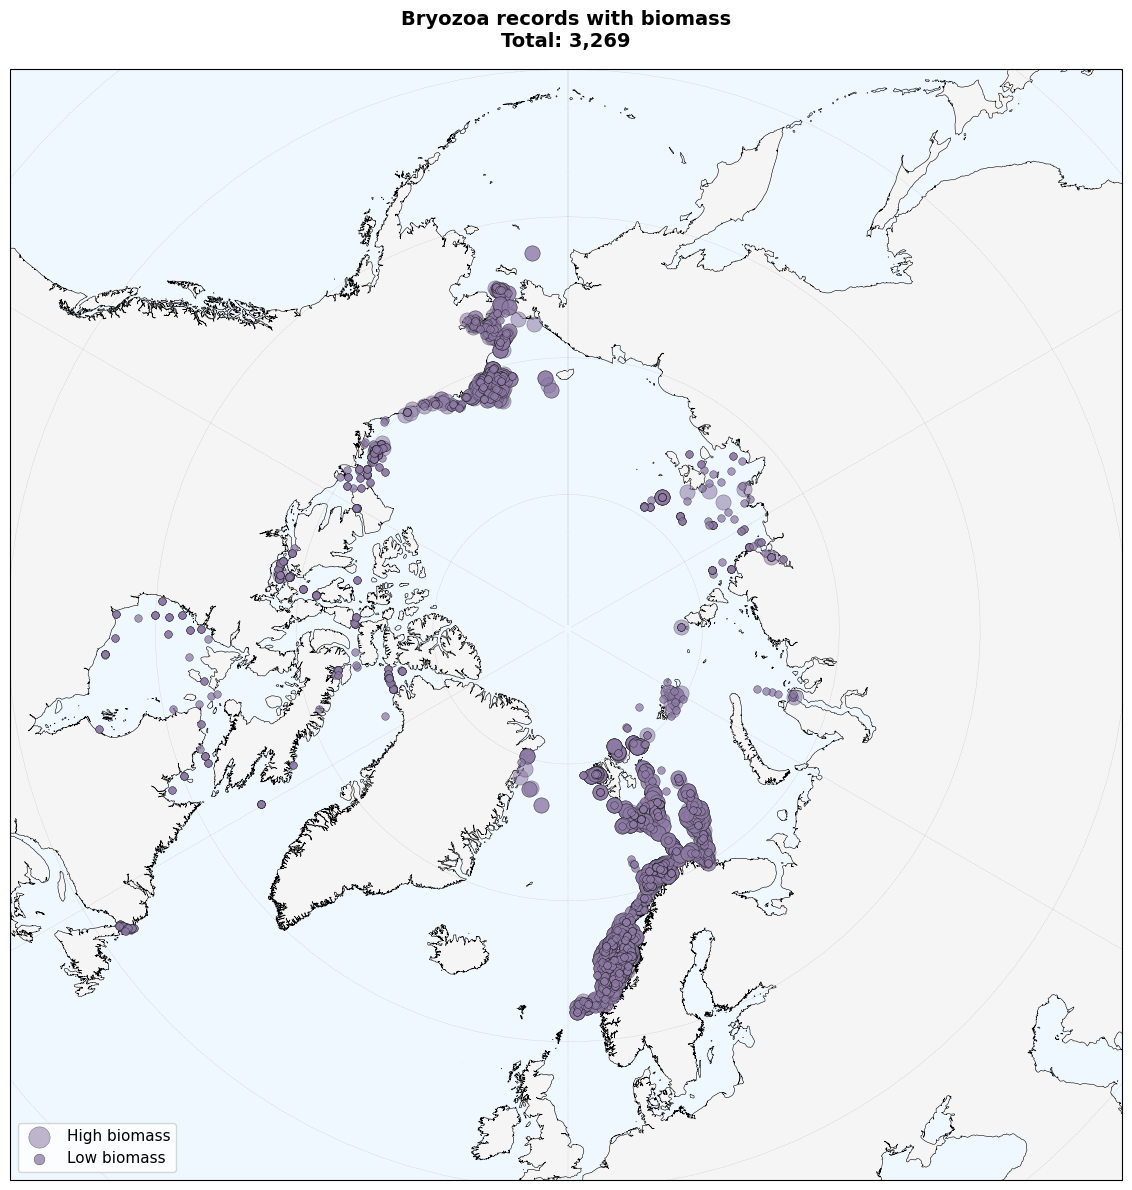

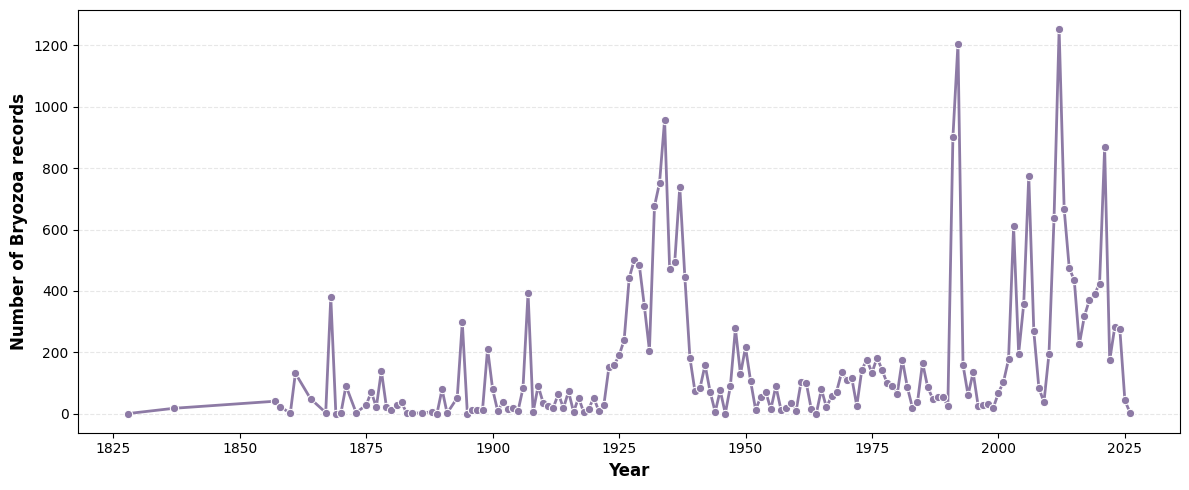

,year,record_count
0,1828,1
1,1837,18
2,1857,41
3,1858,23
4,1860,2
...,...,...
157,2022,174
158,2023,282
159,2024,277
160,2025,44


In [18]:
# Bryozoa maps: distribution + biomass (high/low by median), same pattern as previous taxa

# 1) Build/load Bryozoa subset
if "src" in globals():
    base_df = src
else:
    base_df = pd.read_parquet("Final/merged_all_final.parquet")

bryozoa = base_df[
    base_df["phylum"].astype("string").str.strip().str.lower() == "bryozoa"
] .copy()

bryozoa.to_parquet("VME/bryozoa.parquet", index=False)
print(f"Bryozoa records: {len(bryozoa):,}")

if bryozoa.empty:
    raise ValueError("No records found where phylum == 'Bryozoa'.")

# Fixed style for both maps
map_color = "#8D7AA5"
edge_color_local = "#1F1F1F"
size_high_local = size_high if "size_high" in globals() else 120
size_low_local = size_low if "size_low" in globals() else 30

# 2) Distribution map
df_map = bryozoa.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color=map_color,
    transform=ccrs.PlateCarree(),
    label="Bryozoa",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Bryozoa distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("VME/bryozoa_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = bryozoa.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Bryozoa records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high_local,
        c=map_color,
        alpha=0.55,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low_local,
        c=map_color,
        alpha=0.75,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Bryozoa records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("VME/bryozoa_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
bryozoa_timeline = (
    bryozoa.assign(year=pd.to_numeric(bryozoa["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=bryozoa_timeline, x="year", y="record_count", marker="o", color=map_color, linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Bryozoa records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("VME/bryozoa_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

bryozoa_timeline

# Dataset for Lis

Taxa to include

Cnidarians after 2000 (exclude records without year): 
- Families
    - Primnoidae 
    - Cerianthidae 
    - Coralliidae 
    - Stylasteridae 
    - Alcyoniidae 
    - Pennatulidae 
    - Funiculinidae 
    - Virgulariidae 

Porifera after 2000 (exclude records without year): 
- Families
    - Geodiidae
- Species: 
    - Chondrocladia (Chondrocladia) gigantea (133185) (unaccepted), Chondrocladia (Chondrocladia) grandis (1023293) (accepted)
    - Cladorhiza bathycrinoides (133190)

Siboglinids after 2000 (exclude records without year): 
- Families
    - Siboglinidae

Crinoidea after 2000 (exclude records without year): 
- Orders
    - Isocrinida 
    - Hyocrinida
- Families
    - Eugeniacrinitidae

Columns to include:
-	sourceDatabase 
-	sourceID
-	datasetKey
-	datasetTitle
-	decimalLatitudeStart
-	decimalLongitudeStart
-	year
-	acceptedScientificName
-	phylum
-	class
-	order
-	family
-	genus
-	aphiaID
-	biomass 
-   gear
-	LME

In [20]:
# Create Cnidaria subset for selected families and years, then save to CSV
input_file = "Final/merged_all_final.parquet"
output_file = "VME/subset_cnidaria.csv"

target_families = [
    "Primnoidae",
    "Cerianthidae",
    "Coralliidae",
    "Stylasteridae",
    "Alcyoniidae",
    "Pennatulidae",
    "Funiculinidae",
    "Virgulariidae",
]

selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "largeMarineEcosystem",
]

df = pd.read_parquet(input_file)

missing_cols = [c for c in selected_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

work = df[selected_cols].copy()
work["year_num"] = pd.to_numeric(work["year"], errors="coerce")
work["family_norm"] = work["family"].astype("string").str.strip()

mask = (
    work["family_norm"].isin(target_families)
    & work["year_num"].between(2000, 2026, inclusive="both")
)

subset_cnidaria = work.loc[mask, selected_cols].copy()
subset_cnidaria["year"] = work.loc[mask, "year_num"].astype(int).values

# Normalize punctuation that can interfere with downstream CSV parsing.
subset_cnidaria["datasetTitle"] = (
    subset_cnidaria["datasetTitle"]
    .astype("string")
    .str.replace(";", ",", regex=False)
)
subset_cnidaria["acceptedScientificName"] = (
    subset_cnidaria["acceptedScientificName"]
    .astype("string")
    .str.replace(r"\s*,\s*", " ", regex=True)
)
subset_cnidaria["gear"] = (
    subset_cnidaria["gear"]
    .astype("string")
    .str.replace(";", ",", regex=False)
)
subset_cnidaria.to_csv(output_file, index=False, encoding="utf-8-sig")

# Summary statistics
family_counts = (
    subset_cnidaria["family"]
    .astype("string")
    .str.strip()
    .value_counts()
    .reindex(target_families, fill_value=0)
    .rename_axis("family")
    .reset_index(name="record_count")
)

total_records = len(subset_cnidaria)

print(f"Saved {total_records:,} records to {output_file}")
print("\nRecords per family:")
print(family_counts)
print(f"\nTotal records: {total_records:,}")

Saved 33,453 records to VME/subset_cnidaria.csv

Records per family:
          family  record_count
0     Primnoidae          9034
1   Cerianthidae           170
2    Coralliidae          8282
3  Stylasteridae          7256
4    Alcyoniidae          3508
5   Pennatulidae          1379
6  Funiculinidae           785
7  Virgulariidae          3039

Total records: 33,453


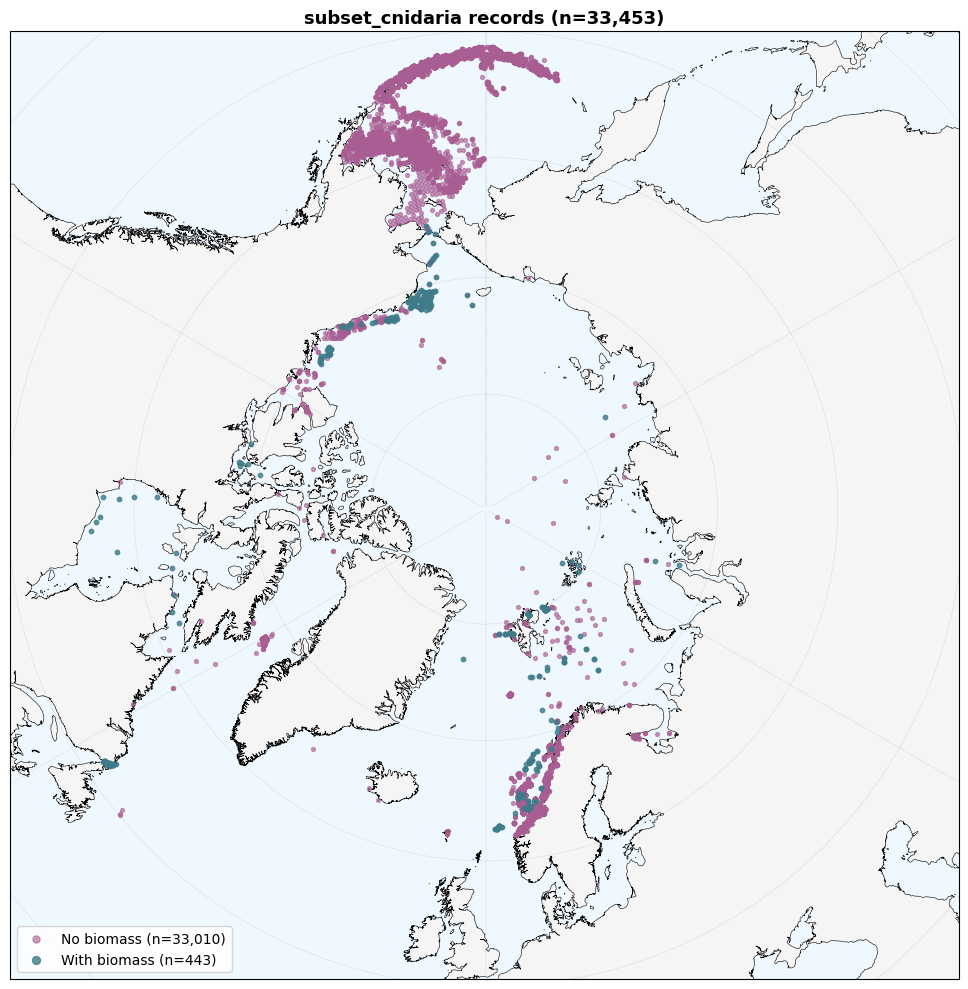

In [21]:
# Load subset_cnidaria from memory or CSV
if "subset_cnidaria" in globals():
    df_map = subset_cnidaria.copy()
else:
    csv_path = output_file if "output_file" in globals() else "VME/subset_cnidaria.csv"
    df_map = pd.read_csv(csv_path)

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag (non-null and non-empty)
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

# Plot (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Records without biomass
no_bio = df_map[~df_map["has_biomass"]]
ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=8,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

# Records with biomass
yes_bio = df_map[df_map["has_biomass"]]
ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=10,
    color="#3F7B89",
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_cnidaria records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [27]:
# Create Porifera subset for Geodiidae family OR selected aphiaIDs, restricted to years 2000–2026
input_file = "Final/merged_all_final.parquet"
output_file = "VME/subset_porifera.csv"

selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "largeMarineEcosystem",
]

target_aphia_ids = {133185, 1023293, 133190}

df = pd.read_parquet(input_file)

missing_cols = [c for c in selected_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

work = df[selected_cols].copy()

# Normalize filter fields
work["year_num"] = pd.to_numeric(work["year"], errors="coerce")
work["family_norm"] = work["family"].astype("string").str.strip().str.lower()
work["aphiaID_num"] = pd.to_numeric(work["aphiaID"], errors="coerce")

year_mask = work["year_num"].between(2000, 2026, inclusive="both").fillna(False)
family_mask = work["family_norm"].eq("geodiidae").fillna(False)
aphia_mask = work["aphiaID_num"].isin(target_aphia_ids).fillna(False)

mask = year_mask & (family_mask | aphia_mask)

subset_porifera = work.loc[mask, selected_cols].copy()
subset_porifera["year"] = work.loc[mask, "year_num"].astype(int).values

# Normalize punctuation that can interfere with downstream CSV parsing.

subset_porifera["gear"] = (
    subset_porifera["gear"]
    .astype("string")
    .str.replace(";", ",", regex=False)
)
subset_porifera.to_csv(output_file, index=False, encoding="utf-8-sig")

# Summary: records per family + total
family_counts = (
    subset_porifera["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

total_records = len(subset_porifera)

# Coverage (% non-missing) per column in subset
def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_df = pd.DataFrame({
    "column": subset_porifera.columns,
    "non_missing": [non_missing_mask(subset_porifera[c]).sum() for c in subset_porifera.columns],
})
coverage_df["total_rows"] = total_records
coverage_df["coverage_percent"] = (coverage_df["non_missing"] / total_records * 100).round(2)
coverage_df = coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {total_records:,} records to {output_file}")
print("\nRecords per family:")
print(family_counts)
print(f"\nTotal records: {total_records:,}")
print("\nColumn coverage (% non-missing):")
print(coverage_df)

Saved 4,474 records to VME/subset_porifera.csv

Records per family:
          family  record_count
0      Geodiidae          4409
1  Cladorhizidae            65

Total records: 4,474

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase         4474        4474            100.00
1                 sourceID         4474        4474            100.00
2               datasetKey         4474        4474            100.00
3             datasetTitle         4474        4474            100.00
4     decimalLatitudeStart         4474        4474            100.00
5    decimalLongitudeStart         4474        4474            100.00
6                     year         4474        4474            100.00
7   acceptedScientificName         4474        4474            100.00
8                   phylum         4474        4474            100.00
9                    class         4474        4474            100.00
10           

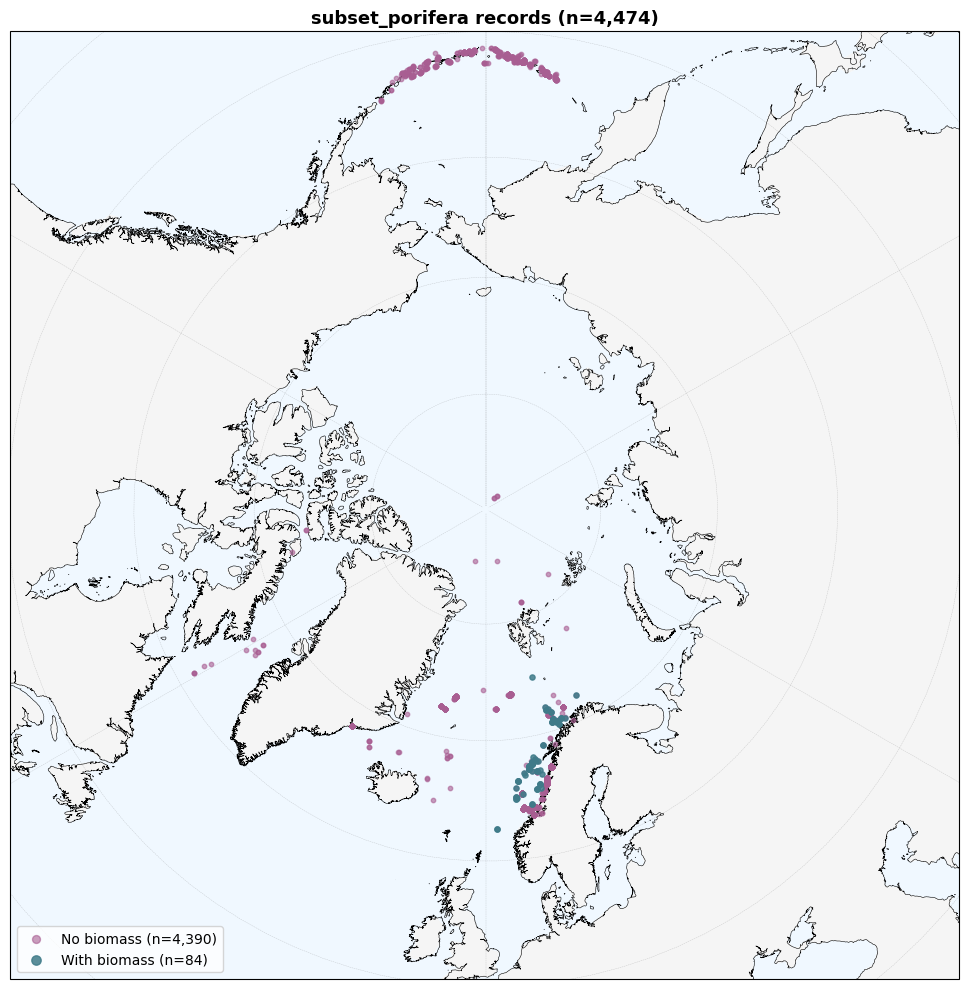

In [28]:
# Map VME/subset_porifera.csv with biomass/non-biomass records in different colors
porifera_csv = "VME/subset_porifera.csv"
df_map = pd.read_csv(porifera_csv)

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

no_bio = df_map[~df_map["has_biomass"]]
yes_bio = df_map[df_map["has_biomass"]]

# Plot (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=10,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=14,
    color="#3F7B89",
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_porifera records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [30]:
# Create Siboglinidae subset for years 2000â€“2026 and save to CSV
sib_input_file = "Final/merged_all_final.parquet"
sib_output_file = "VME/subset_siboglinids.csv"

sib_selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "largeMarineEcosystem",
]

sib_df = pd.read_parquet(sib_input_file)

missing_cols = [c for c in sib_selected_cols if c not in sib_df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

sib_work = sib_df[sib_selected_cols].copy()
sib_work["year_num"] = pd.to_numeric(sib_work["year"], errors="coerce")
sib_work["family_norm"] = sib_work["family"].astype("string").str.strip().str.lower()

sib_mask = (
    sib_work["family_norm"].eq("siboglinidae")
    & sib_work["year_num"].between(2000, 2026, inclusive="both")
)

subset_siboglinids = sib_work.loc[sib_mask, sib_selected_cols].copy()
subset_siboglinids["year"] = sib_work.loc[sib_mask, "year_num"].astype(int).values

subset_siboglinids.to_csv(sib_output_file, index=False)

# Summary: records per family and total
sib_family_counts = (
    subset_siboglinids["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

sib_total_records = len(subset_siboglinids)

# Coverage (% non-missing) per column
def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

sib_coverage_df = pd.DataFrame({
    "column": subset_siboglinids.columns,
    "non_missing": [non_missing_mask(subset_siboglinids[c]).sum() for c in subset_siboglinids.columns],
})
sib_coverage_df["total_rows"] = sib_total_records
sib_coverage_df["coverage_percent"] = (sib_coverage_df["non_missing"] / sib_total_records * 100).round(2)
sib_coverage_df = sib_coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {sib_total_records:,} records to {sib_output_file}")
print("\nRecords per family:")
print(sib_family_counts)
print(f"\nTotal records: {sib_total_records:,}")
print("\nColumn coverage (% non-missing):")
print(sib_coverage_df)

Saved 3,524 records to VME/subset_siboglinids.csv

Records per family:
         family  record_count
0  Siboglinidae          3524

Total records: 3,524

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase         3524        3524            100.00
1                 sourceID         3524        3524            100.00
2               datasetKey         3524        3524            100.00
3             datasetTitle         3524        3524            100.00
4     decimalLatitudeStart         3524        3524            100.00
5    decimalLongitudeStart         3524        3524            100.00
6                     year         3524        3524            100.00
7   acceptedScientificName         3524        3524            100.00
8                   phylum         3524        3524            100.00
9                    class         3524        3524            100.00
10                   order         3524    

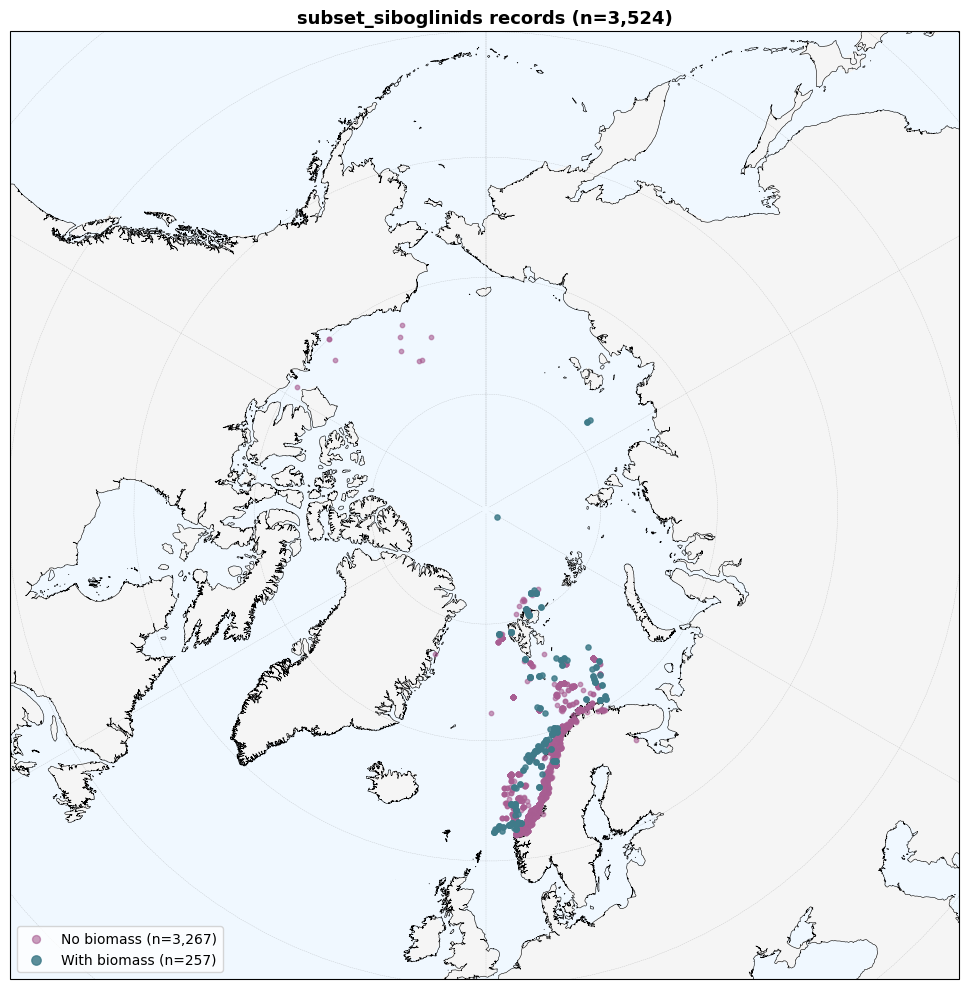

In [31]:
# Map siboglinids_cnidaria.csv with biomass/non-biomass records in different colors
csv_file = "VME/subset_siboglinids.csv"
df_map = pd.read_csv(csv_file)

required_cols = ["decimalLatitudeStart", "decimalLongitudeStart", "biomass"]
missing_cols = [c for c in required_cols if c not in df_map.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in {csv_file}: {missing_cols}")

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag (non-null and non-empty)
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

no_bio = df_map[~df_map["has_biomass"]]
yes_bio = df_map[df_map["has_biomass"]]

# Plot map (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=10,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=14,
    color="#3F7B89",
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_siboglinids records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

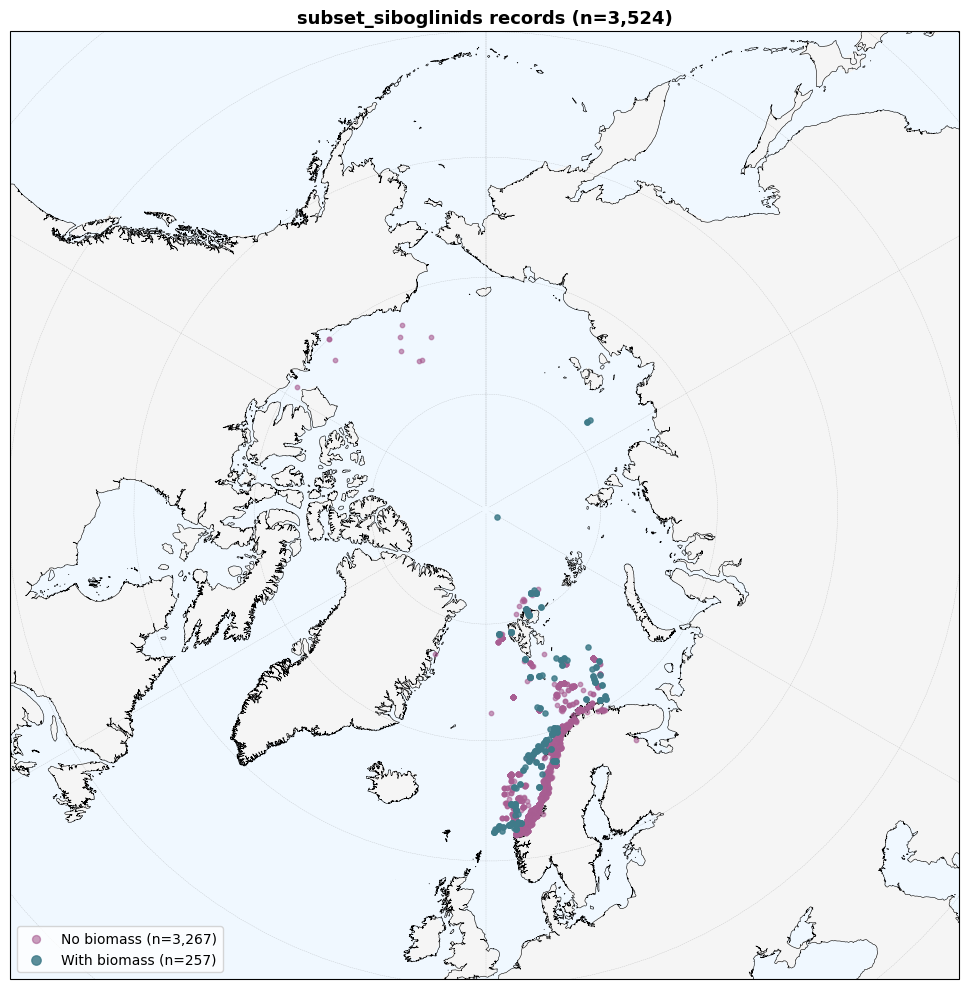

In [32]:
# Map siboglinids_cnidaria.csv with biomass/non-biomass records in different colors
csv_file = "VME/subset_siboglinids.csv"
df_map = pd.read_csv(csv_file)

required_cols = ["decimalLatitudeStart", "decimalLongitudeStart", "biomass"]
missing_cols = [c for c in required_cols if c not in df_map.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in {csv_file}: {missing_cols}")

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag (non-null and non-empty)
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

no_bio = df_map[~df_map["has_biomass"]]
yes_bio = df_map[df_map["has_biomass"]]

# Plot map (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=10,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=14,
    color="#3F7B89",
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_siboglinids records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [36]:
# Create Crinoidea subset (orders: Isocrinida/Hyocrinida AND family: Eugeniacrinitidae), years 2000–2026
crinoid_input_file = input_file if "input_file" in globals() else "Final/merged_all_final.parquet"
crinoid_output_file = "VME/subset_crinoids.csv"

crinoid_selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "largeMarineEcosystem",
]

target_orders = {"isocrinida", "hyocrinida"}
target_family = "eugeniacrinitidae"

cr_df = pd.read_parquet(crinoid_input_file)

missing_cols = [c for c in crinoid_selected_cols if c not in cr_df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

cr_work = cr_df[crinoid_selected_cols].copy()
cr_work["year_num"] = pd.to_numeric(cr_work["year"], errors="coerce")
cr_work["order_norm"] = cr_work["order"].astype("string").str.strip().str.lower()
cr_work["family_norm"] = cr_work["family"].astype("string").str.strip().str.lower()

year_mask = cr_work["year_num"].between(2000, 2026, inclusive="both").fillna(False)
order_mask = cr_work["order_norm"].isin(target_orders).fillna(False)
family_mask = cr_work["family_norm"].eq(target_family).fillna(False)

cr_mask = year_mask & order_mask & family_mask

subset_crinoids = cr_work.loc[cr_mask, crinoid_selected_cols].copy()
subset_crinoids["year"] = cr_work.loc[cr_mask, "year_num"].astype(int).values

subset_crinoids.to_csv(crinoid_output_file, index=False)

# Summary stats
cr_family_counts = (
    subset_crinoids["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

cr_total_records = len(subset_crinoids)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

cr_coverage_df = pd.DataFrame({
    "column": subset_crinoids.columns,
    "non_missing": [non_missing_mask(subset_crinoids[c]).sum() for c in subset_crinoids.columns],
})
cr_coverage_df["total_rows"] = cr_total_records
cr_coverage_df["coverage_percent"] = (
    (cr_coverage_df["non_missing"] / cr_total_records * 100).round(2)
    if cr_total_records > 0
    else 0.0
)
cr_coverage_df = cr_coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {cr_total_records:,} records to {crinoid_output_file}")
print("\nRecords per family:")
print(cr_family_counts)
print(f"\nTotal records: {cr_total_records:,}")
print("\nColumn coverage (% non-missing):")
print(cr_coverage_df)

Saved 0 records to VME/subset_crinoids.csv

Records per family:
Empty DataFrame
Columns: [family, record_count]
Index: []

Total records: 0

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase            0           0               0.0
1                 sourceID            0           0               0.0
2               datasetKey            0           0               0.0
3             datasetTitle            0           0               0.0
4     decimalLatitudeStart            0           0               0.0
5    decimalLongitudeStart            0           0               0.0
6                     year            0           0               0.0
7   acceptedScientificName            0           0               0.0
8                   phylum            0           0               0.0
9                    class            0           0               0.0
10                   order            0           0     

In [37]:
# Overview of orders and families within class Crinoidea
crino_file = input_file if "input_file" in globals() else "Final/merged_all_final.parquet"
df_crino = pd.read_parquet(crino_file)

# Filter class = Crinoidea (case/whitespace robust)
crino = df_crino[
    df_crino["class"].astype("string").str.strip().str.lower().eq("crinoidea")
].copy()

print(f"Total Crinoidea records: {len(crino):,}")

# Clean order/family labels
crino["order_clean"] = (
    crino["order"].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
)
crino["family_clean"] = (
    crino["family"].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
)

# 1) Orders overview
crino_order_counts = (
    crino["order_clean"]
    .value_counts(dropna=False)
    .rename_axis("order")
    .reset_index(name="record_count")
)

# 2) Families overview
crino_family_counts = (
    crino["family_clean"]
    .value_counts(dropna=False)
    .rename_axis("family")
    .reset_index(name="record_count")
)

# 3) Order x Family overview
crino_order_family_counts = (
    crino.groupby(["order_clean", "family_clean"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values(["order_clean", "record_count"], ascending=[True, False])
)

print("\nOrders in Crinoidea:")
print(crino_order_counts)

print("\nFamilies in Crinoidea:")
print(crino_family_counts)

print("\nOrder Ã— Family combinations in Crinoidea:")
print(crino_order_family_counts)

# Optional: save outputs
crino_order_counts.to_csv("VME/crinoidea_orders_overview.csv", index=False)
crino_family_counts.to_csv("VME/crinoidea_families_overview.csv", index=False)
crino_order_family_counts.to_csv("VME/crinoidea_order_family_overview.csv", index=False)

Total Crinoidea records: 3,426

Orders in Crinoidea:
        order  record_count
0  Comatulida          2750
1     Unknown           675
2  Hyocrinida             1

Families in Crinoidea:
               family  record_count
0         Antedonidae          2225
1             Unknown           715
2       Bathycrinidae           392
3       Rhizocrinidae            77
4    Thalassometridae             4
5   Bourgueticrinidae             4
6         Comatulidae             3
7        Zenometridae             2
8     Charitometridae             2
9         Hyocrinidae             1
10     Tropiometridae             1

Order Ã— Family combinations in Crinoidea:
   order_clean       family_clean  record_count
0   Comatulida        Antedonidae          2225
1   Comatulida      Bathycrinidae           392
5   Comatulida      Rhizocrinidae            77
8   Comatulida            Unknown            40
2   Comatulida  Bourgueticrinidae             4
6   Comatulida   Thalassometridae             4

In [38]:
# Years with records where order == "Hyocrinida"
source_df = sib_df if "sib_df" in globals() else pd.read_parquet(input_file)

hyocrinida_rows = source_df[
	source_df["order"].astype("string").str.strip().str.lower().eq("hyocrinida")
].copy()

hyocrinida_rows["year_num"] = pd.to_numeric(hyocrinida_rows["year"], errors="coerce")
years = sorted(hyocrinida_rows["year_num"].dropna().astype(int).unique().tolist())

print("Years with Hyocrinida records:", years)
print("Total Hyocrinida records:", len(hyocrinida_rows))
print(
	hyocrinida_rows["year_num"]
	.dropna()
	.astype(int)
	.value_counts()
	.sort_index()
	.rename("record_count")
)

Years with Hyocrinida records: [1990]
Total Hyocrinida records: 1
year_num
1990    1
Name: record_count, dtype: int64


In [39]:
# Merge selected subset files into one CSV, then report column coverage and sourceDatabase proportions
files_to_merge = ["VME/subset_siboglinids.csv", "VME/subset_porifera.csv", "VME/subset_cnidaria.csv"]
merged_output_file = "VME/subset_merged_vme.csv"

dfs = []
for f in files_to_merge:
	if not os.path.exists(f):
		raise FileNotFoundError(f"File not found: {f}")
	dfs.append(pd.read_csv(f))

merged_df = pd.concat(dfs, ignore_index=True, sort=False)
merged_df.to_csv(merged_output_file, index=False)

def non_missing_mask(s):
	m = s.notna()
	if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
		m &= s.astype("string").str.strip().ne("")
	return m

# Column coverage (% non-missing)
total_rows = len(merged_df)
coverage_df = pd.DataFrame({
	"column": merged_df.columns,
	"non_missing": [non_missing_mask(merged_df[c]).sum() for c in merged_df.columns],
})
coverage_df["total_rows"] = total_rows
coverage_df["coverage_percent"] = (coverage_df["non_missing"] / total_rows * 100).round(2)
coverage_df = coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

# Proportion of records by sourceDatabase
if "sourceDatabase" not in merged_df.columns:
	raise KeyError("Column 'sourceDatabase' not found in merged data.")

source_stats = (
	merged_df["sourceDatabase"]
	.astype("string")
	.str.strip()
	.replace("", pd.NA)
	.fillna("Unknown")
	.value_counts(dropna=False)
	.rename_axis("sourceDatabase")
	.reset_index(name="record_count")
)
source_stats["proportion_percent"] = (source_stats["record_count"] / total_rows * 100).round(2)

# Optional outputs
coverage_df.to_csv("VME/subset_merged_column_coverage.csv", index=False)
source_stats.to_csv("VME/subset_merged_source_proportion.csv", index=False)

print(f"Saved merged file: {merged_output_file} ({total_rows:,} rows)")
print("\nColumn coverage (% non-missing):")
print(coverage_df)
print("\nsourceDatabase distribution:")
print(source_stats)

C:\Users\hamod4691\AppData\Local\Temp\ipykernel_24164\3365726843.py:9: DtypeWarning: Columns (0: sourceID) have mixed types. Specify dtype option on import or set low_memory=False.
  dfs.append(pd.read_csv(f))


Saved merged file: VME/subset_merged_vme.csv (41,451 rows)

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase        41451       41451            100.00
1               datasetKey        41451       41451            100.00
2             datasetTitle        41451       41451            100.00
3     decimalLatitudeStart        41451       41451            100.00
4    decimalLongitudeStart        41451       41451            100.00
5   acceptedScientificName        41451       41451            100.00
6                     year        41451       41451            100.00
7                   phylum        41451       41451            100.00
8                    class        41451       41451            100.00
9     largeMarineEcosystem        41451       41451            100.00
10                   order        41451       41451            100.00
11                  family        41451       41451            100.

In [40]:
# Build datasetKey summary with sourceDatabase and number of records
df_merged = pd.read_csv(merged_output_file)

summary_datasetkey = (
    df_merged.assign(
        datasetKey=df_merged["datasetKey"].astype("string").str.strip(),
        sourceDatabase=df_merged["sourceDatabase"].astype("string").str.strip(),
    )
    .replace({"datasetKey": {"": pd.NA}, "sourceDatabase": {"": pd.NA}})
    .dropna(subset=["datasetKey", "sourceDatabase"])
    .groupby(["datasetKey", "sourceDatabase"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

out_file = "VME/datasetKey_record_counts.csv"
summary_datasetkey.to_csv(out_file, index=False)

print(f"Saved {len(summary_datasetkey):,} rows to {out_file}")
summary_datasetkey.head(20)

Saved 106 rows to VME/datasetKey_record_counts.csv


C:\Users\hamod4691\AppData\Local\Temp\ipykernel_24164\3042457602.py:2: DtypeWarning: Columns (0: sourceID) have mixed types. Specify dtype option on import or set low_memory=False.
  df_merged = pd.read_csv(merged_output_file)


,datasetKey,sourceDatabase,record_count
98,df8e3fb8-3da7-4104-a866-748f6da20a3c,GBIF,15103
80,b6b4502f-ffc8-4048-a91b-af502288faa8,GBIF,5482
103,f5a4799e-dc24-4807-89d9-01da47d52e3b,OBIS,5124
19,46293000-ddd1-4c32-a1e7-b5e793223ecd,GBIF,3023
37,85093767-a3f4-4c88-8f95-434f28575758,GBIF,1245
6,18b7c5c7-9814-4dc4-a8aa-833e91969358,GBIF,1033
86,bed78790-cbec-44af-82af-fe78e9692287,GBIF,830
23,51e8ed5a-e5ae-4e75-b70a-a783a5487717,GBIF,807
21,4b667f4a-2c2c-401e-8fbb-9be0bdf41421,OBIS,786
81,b87f3225-cd11-4a8f-b552-ba25aab389dc,GBIF,705


# Check which ones coincide with Lis' list